In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/LIFEMap_DATA_LABELS_2026-09-04_1216.csv', sep='\t')

# Creazione dataset con consensi espliciti
colonna_consenso = 'Il partecipante/genitore se minore/rappresentante legale ha fornito il consenso a partecipare allo studio? ATTENZIONE: è necessario rispondere Si per procedere con la compilazione della eCRF.'
df_consensi = df.loc[df[colonna_consenso] == 'Yes'].copy()

In [6]:
# Cambio nomi delle patologie

mappa_nomi_patologie = {
    df_consensi.columns[6]: 'Diabetes Mellitus',
    df_consensi.columns[7]: 'Dyslipidemia',
    df_consensi.columns[9]: 'Cardiovascular Disease',
    df_consensi.columns[10]: 'Arterial Hypertension'
    }

df_consensi.rename(columns=mappa_nomi_patologie, inplace=True)

lista_patologie = [df_consensi.columns[i] for i in range(6, 8)] + [df_consensi.columns[i] for i in range(9, 11)]

for c, patologia in enumerate(lista_patologie):
  print(f'{c} = {patologia}')

0 = Diabetes Mellitus
1 = Dyslipidemia
2 = Cardiovascular Disease
3 = Arterial Hypertension


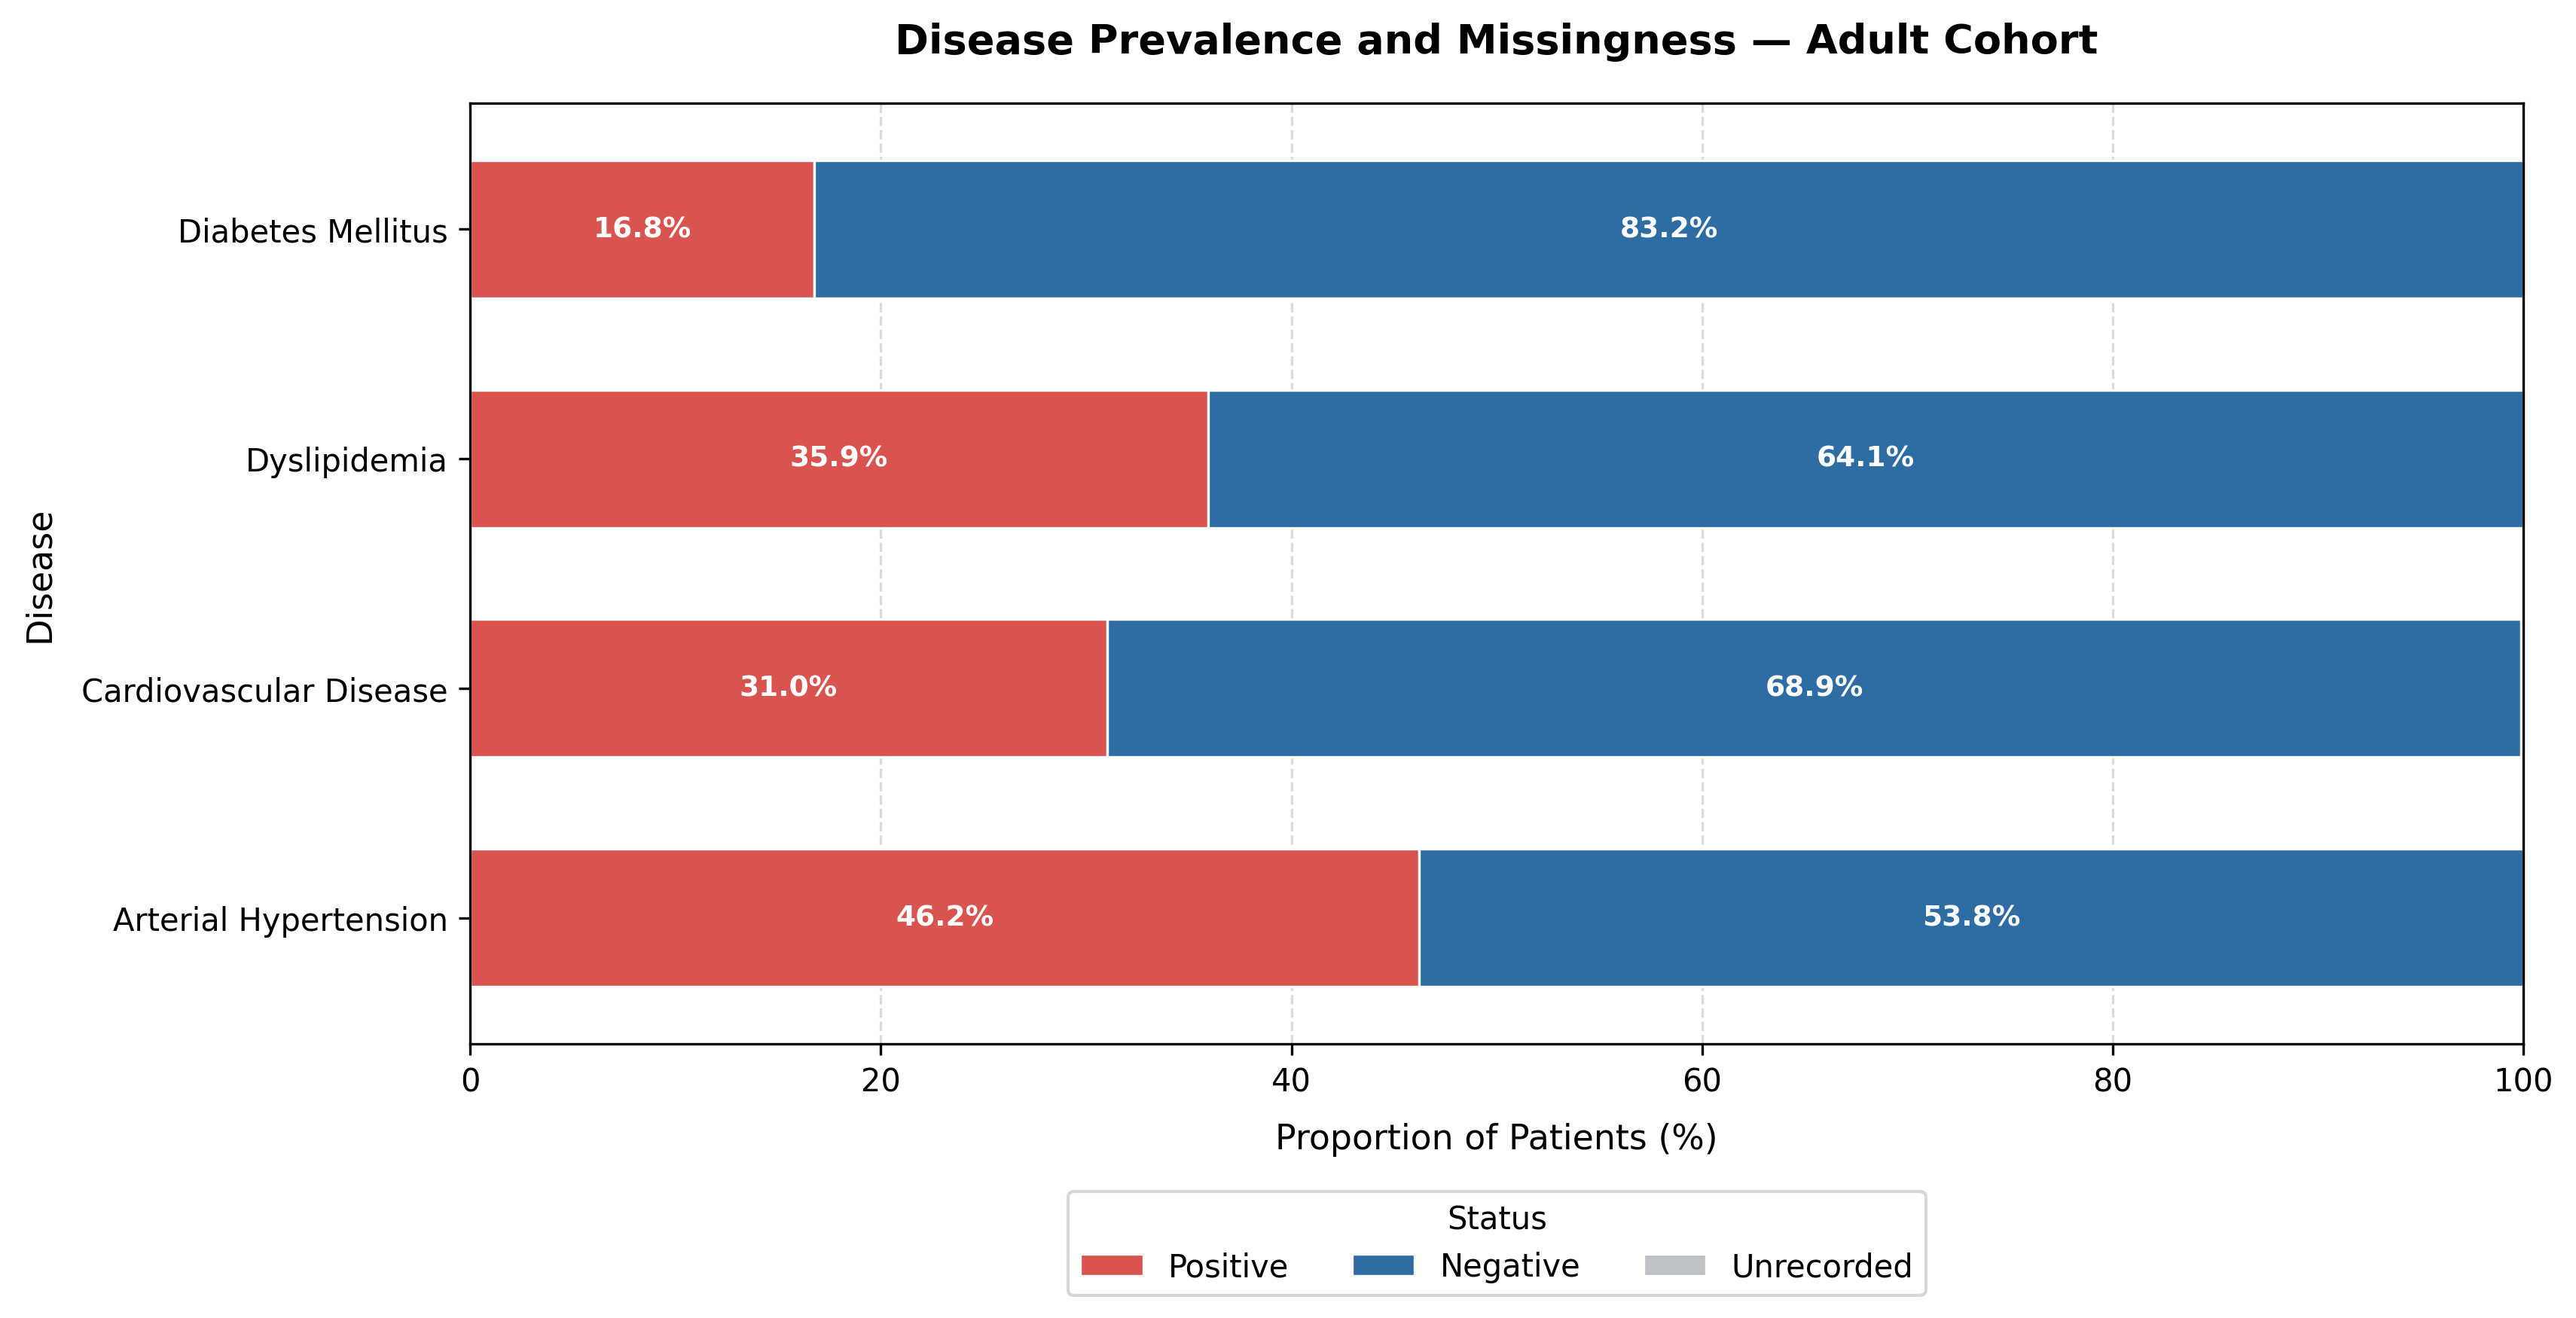

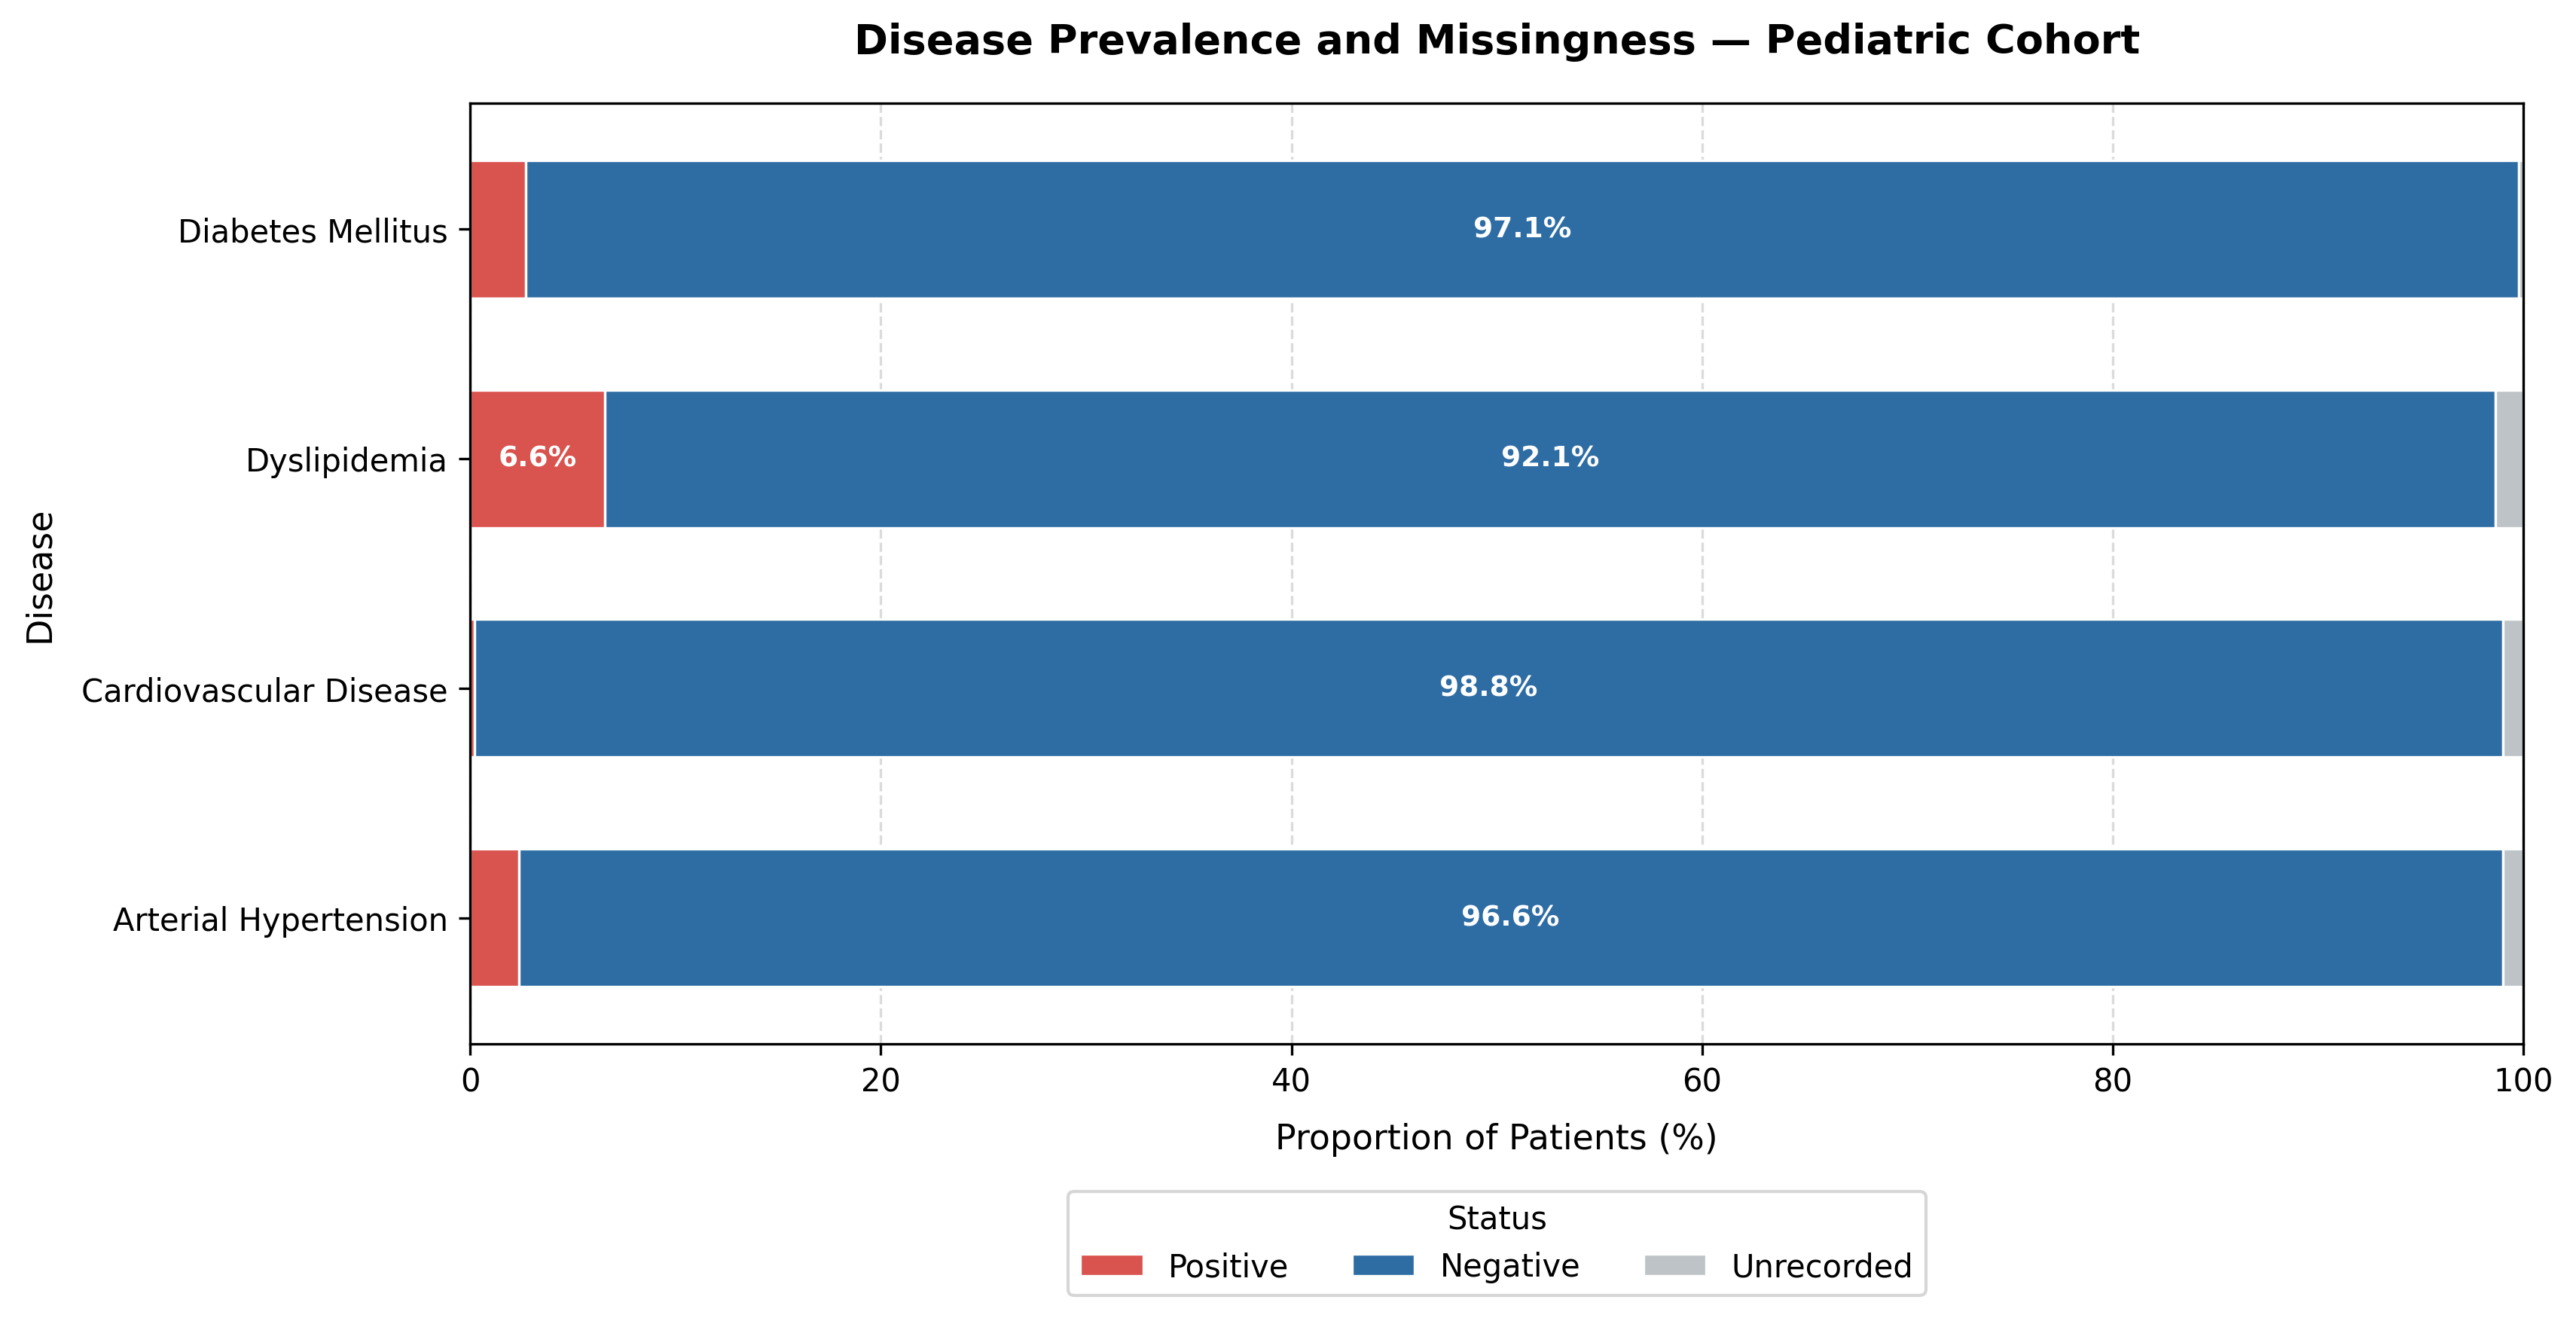

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Divisione dataset per tipo sondaggio
df_adulti = df_consensi.loc[df_consensi['Event Name'] == 'Valutazione (Arm 1: Adulto)']
df_bambini = df_consensi.loc[df_consensi['Event Name'] == 'Valutazione (Arm 2: Bambino)']

datasets = {
    'Adult Cohort': df_adulti,
    'Pediatric Cohort': df_bambini
}

colori = ['#d9534f', '#2e6da4', '#bdc3c7']

# Calcolo distribuzioni
for nome_gruppo, df_gruppo in datasets.items():
  lista_percentuali = []

  for patologia in lista_patologie:
    conteggi = (
        df_gruppo[patologia].value_counts(dropna=False, normalize=True) * 100
    )

    pct_si = conteggi.get('Si', 0.0)
    pct_no = conteggi.get('No', 0.0)
    pct_nan = conteggi.get(np.nan, 0.0)

    lista_percentuali.append({
        'Pathology': patologia,
        '% Yes': pct_si,
        '% No': pct_no,
        '% Missing': pct_nan,
    })

  df_percentuali = pd.DataFrame(lista_percentuali).set_index('Pathology')

  # Creazione figura
  fig, ax = plt.subplots(figsize=(11.5, 6), dpi=300)
  df_grafico = df_percentuali[['% Yes', '% No', '% Missing']]

  df_grafico.plot(
      kind='barh',
      stacked=True,
      color=colori,
      ax=ax,
      width=0.6,
      edgecolor='white',
      linewidth=0.8,
  )

  soglia_minima_etichetta = 3.5

  for c in ax.containers:
    labels = [
        f'{v:.1f}%' if v >= soglia_minima_etichetta else ''
        for v in c.datavalues
    ]
    ax.bar_label(
        c,
        labels=labels,
        label_type='center',
        color='white',
        fontsize=9,
        fontweight='bold',
    )

  # Configurazione assi e stile accademico
  ax.set_title(
      f'Disease Prevalence and Missingness — {nome_gruppo}',
      fontsize=13,
      fontweight='bold',
      pad=16,
  )
  ax.set_xlabel('Proportion of Patients (%)', fontsize=11, labelpad=8)
  ax.set_ylabel('Disease', fontsize=11, labelpad=8)
  ax.set_xlim(0, 100)

  ax.grid(axis='x', linestyle='--', alpha=0.45)
  ax.set_axisbelow(True)
  ax.invert_yaxis()

  # Posizionamento legenda
  ax.legend(
      ['Positive', 'Negative', 'Unrecorded'],
      title='Status',
      title_fontsize=10,
      loc='upper center',
      bbox_to_anchor=(0.5, -0.14),
      ncol=3,
      frameon=True,
      fontsize=10,
  )

  plt.tight_layout()

  # Salvataggio
  nome_file = nome_gruppo.lower().replace(' ', '_').replace('(', '').replace(')', '').replace('+', 'and')
  plt.savefig(f"prevalence_{nome_file}.pdf", bbox_inches='tight')

  plt.show()

In [9]:
# Modifica parametri errati

parametri_corporei = ['Età alla valutazione', 'Peso (kg)', 'Altezza (m)', 'BMI (kg/m2)', 'Peso alla nascita (kg)']
valori_ematici = df_consensi.columns.to_list()[171:191]

print('Prima della modifica\n', df_consensi[parametri_corporei].describe())

# Modifica parametri corporei
df_consensi.loc[df_consensi['Altezza (m)'] >= 2, 'Altezza (m)'] = df_consensi['Altezza (m)'] / 100
df_consensi['Anno di nascita'] = pd.to_numeric(df_consensi['Anno di nascita'], errors='coerce')

# Correzione singoli outlier con valori errati
df_consensi.loc[df_consensi['Record ID'].astype(str) == '1002-152', 'Peso (kg)'] = np.nan
df_consensi.loc[df_consensi['Record ID'].astype(str) == '1003-86', 'Altezza (m)'] = np.nan
df_consensi.loc[df_consensi['Record ID'].astype(str) == '1001-277', 'Circonferenza vita (cm)'] = np.nan
df_consensi.loc[df_consensi['Record ID'].astype(str) == '1003-354', 'Circonferenza vita (cm)'] = np.nan
df_consensi.loc[df_consensi['Record ID'].astype(str) == '1003-397', 'Circonferenza vita (cm)'] = np.nan

# Calcolo BMI corretto
df_consensi['Peso (kg)'] = pd.to_numeric(df_consensi['Peso (kg)'], errors='coerce')
df_consensi['Altezza (m)'] = pd.to_numeric(df_consensi['Altezza (m)'], errors='coerce')
condizione_valida = df_consensi['Altezza (m)'].notna() & df_consensi['Peso (kg)'].notna()
df_consensi['BMI (kg/m2)'] = np.where(condizione_valida, (df_consensi['Peso (kg)'] / (df_consensi['Altezza (m)'] ** 2)), np.nan)

print("=" * 30)
print('Dopo la modifica\n', df_consensi[parametri_corporei].describe())

print("=" * 30)
print('Prima della modifica\n', df_consensi[valori_ematici].describe())
df_consensi[valori_ematici].describe().to_excel("pre_modifica.xlsx")

# Sostituzione degli 0 con NaN
colonne_zero_to_nan = ['Piastrine (10*9/L)', 'Colesterolo totale (mg/dl)', 'HDL (mg/dl)', 'LDL (mg/dl)', 'Trigliceridi (mg/dl)', 'Glicemia a digiuno (mg/dl)', 'ALT (U/l)', 'AST (U/l)', 'LDH (U/l)']
df_consensi[colonne_zero_to_nan] = df_consensi[colonne_zero_to_nan].replace(0, np.nan)

# Modifica valori ematici
df_consensi['Hb (g/dl)'] = np.where(df_consensi['Hb (g/dl)'] > 25.0, df_consensi['Hb (g/dl)'] / 10.0, df_consensi['Hb (g/dl)'])
df_consensi['Leucociti (10*9/L)'] = np.where(df_consensi['Leucociti (10*9/L)'] > 100.0, df_consensi['Leucociti (10*9/L)'] / 1000.0, df_consensi['Leucociti (10*9/L)'])
df_consensi['Neutrofili (10*9/L)'] = np.where(df_consensi['Neutrofili (10*9/L)'] > 50.0, df_consensi['Neutrofili (10*9/L)'] / 1000.0, df_consensi['Neutrofili (10*9/L)'])
df_consensi['Linfociti (10*9/L)'] = np.where(df_consensi['Linfociti (10*9/L)'] > 20.0, df_consensi['Linfociti (10*9/L)'] / 1000.0, df_consensi['Linfociti (10*9/L)'])
df_consensi['Piastrine (10*9/L)'] = np.where(df_consensi['Piastrine (10*9/L)'] > 1500.0, df_consensi['Piastrine (10*9/L)'] / 1000.0, df_consensi['Piastrine (10*9/L)'])
df_consensi['Creatinina (mg/dl)'] = np.where(df_consensi['Creatinina (mg/dl)'] > 20.0, df_consensi['Creatinina (mg/dl)'] / 10.0, df_consensi['Creatinina (mg/dl)'])

print("=" * 30)
print('Dopo la modifica\n', df_consensi[valori_ematici].describe())
df_consensi[valori_ematici].describe().to_excel("dopo_modifica.xlsx")

Prima della modifica
        Età alla valutazione    Peso (kg)  Altezza (m)  BMI (kg/m2)  \
count           1678.000000  1456.000000  1438.000000  1438.000000   
mean              41.326579    67.597054     2.261067    25.919066   
std               26.146268    20.536583    10.149007     6.595815   
min                2.000000     1.660000     0.810000     0.001837   
25%               14.000000    55.975000     1.550000    21.677333   
50%               44.000000    67.000000     1.630000    25.381469   
75%               66.000000    80.000000     1.700000    29.296875   
max               97.000000   184.000000   172.000000    75.608153   

       Peso alla nascita (kg)  
count              596.000000  
mean               661.191443  
std               1312.604166  
min                  0.880000  
25%                  3.050000  
50%                  3.455000  
75%                  4.042500  
max               4340.000000  
Dopo la modifica
        Età alla valutazione    Peso (kg) 

In [10]:
#Creazione liste

risorse = 'Con le risorse finanziarie a tua disposizione (provenienti dal tuo reddito o da quello della tua famiglia), indichi con un voto da 1 a 5 quanto riesci a soddisfare le esigenze della tua attuale situazione di vita?'
cliniche_continue = ['Quanti giorni a settimana, mediamente, ha praticato attività fisica di intensità moderata/elevata (es. nuotare, correre, palestra, sport, ecc..).   Si intende una attività che aumenta la frequenza cardiaca e/o aumenta la sudorazione corporea.',
                    'Età alla valutazione',
                    'Peso (kg)',
                    'Altezza (m)',
                    'BMI (kg/m2)',
                    'Circonferenza vita (cm)',
                    'Pressione arteriosa sistolica mmHg',
                    'Pressione arteriosa diastolica mmHg',
                    'Hb (g/dl)',
                    'Leucociti (10*9/L)',
                    'Neutrofili (10*9/L)',
                    'Linfociti (10*9/L)',
                    'Piastrine (10*9/L)',
                    'Creatinina (mg/dl)',
                    'ALT (U/l)',
                    'AST (U/l)',
                    'Istruzione',
                     risorse
                     ]
lista_madre = df_consensi.columns.tolist()[211:219]
lista_padre = df_consensi.columns.tolist()[225:233]
lista_fratelli = df_consensi.columns.tolist()[236:244]
lista_nonni = df_consensi.columns.tolist()[247:255]
lista_parenti = lista_madre + lista_padre + lista_fratelli + lista_nonni
lavoro_esposizioni = df_consensi.columns.tolist()[264:287]
lista_alimentazione_adulti = df_consensi.columns.tolist()[289:303]
lista_alimentazione_bambini = df_consensi.columns.tolist()[305:321]
lista_alimentazione_categoriche = lista_alimentazione_adulti + df_consensi.columns.tolist()[305:309] + df_consensi.columns.tolist()[310:311] + df_consensi.columns.tolist()[312:316] + df_consensi.columns.tolist()[317:321]
lista_alimentazione_continue = df_consensi.columns.tolist()[309:310] + df_consensi.columns.tolist()[311:312] + df_consensi.columns.tolist()[316:317]

In [11]:
# Codifica ed imputazione

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer, OrdinalEncoder
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.compose import ColumnTransformer, make_column_selector

df_model_data = df_consensi.copy()

# Encoding dei target
df_model_data[lista_patologie] = df_model_data[lista_patologie].replace({'Si': 1, 'No': 0}).fillna(0).astype(int)

# Imputazione tramite altri valori del sesso biologico
mancanti = df_model_data['Sesso biologico alla nascita'].isna()
df_model_data.loc[mancanti & (df_model_data['Relazione di parentela'] == 'Padre'), 'Sesso biologico alla nascita'] = 'Maschio'
df_model_data.loc[mancanti & (df_model_data['Relazione di parentela'] == 'Madre'), 'Sesso biologico alla nascita'] = 'Femmina'

# Encoding del sesso biologico
df_model_data[["Sesso biologico alla nascita"]] = df_model_data[["Sesso biologico alla nascita"]].replace({'Maschio': 1, 'Femmina': 0}).fillna(0).astype(int)

# Imputazione del sesso biologico
imputerKnn = KNNImputer()
df_model_data[["Sesso biologico alla nascita"]] = imputerKnn.fit_transform(df_model_data[["Sesso biologico alla nascita"]])

# Arrotondamento per riportare le colonne binarie a 0 e 1
df_model_data[["Sesso biologico alla nascita"]] = (df_model_data[["Sesso biologico alla nascita"]] >= 0.5).astype(int)

# Encoding dell'istruzione
df_model_data[['Istruzione']] = df_model_data[['Istruzione']].replace({'Scuola primaria': 0, 'Scuola secondaria di primo grado': 1, 'Liceo, istituto tecnico o professionale': 2, 'Laurea': 3, 'Dottorato': 4})

# Encoding delle risorse finanziarie
df_model_data[[risorse]] = df_model_data[[risorse]].replace({'1 (con molta difficoltà)': 1, '5 (senza difficoltà)': 5})

# Imputazione delle variabili continue
imputerKnn = KNNImputer()
df_model_data[cliniche_continue] = imputerKnn.fit_transform(df_model_data[cliniche_continue])

# Rimozione dell'età dalla lista di variabili continue perché verrà trattata come categorica
if 'Età alla valutazione' in cliniche_continue:
    cliniche_continue.remove('Età alla valutazione')

# Encoding delle variabili sui parenti
df_model_data[lista_parenti] = df_model_data[lista_parenti].replace({'Checked': 1, 'Unchecked': 0}).astype(int)

# Imputazione fumo
imputerModa = SimpleImputer(strategy='most_frequent')
df_model_data[["E' un fumatore?"]] = imputerModa.fit_transform(df_model_data[["E' un fumatore?"]])

# Encoding fumo
df_model_data = pd.get_dummies(
    df_model_data,
    columns=["E' un fumatore?"],
    prefix="Fumo_",
    drop_first=False,
    dtype=int
)

colonne_nominali = ["Occupazione", "Con chi vive?"]
df_model_data[colonne_nominali] = imputerModa.fit_transform(
    df_model_data[colonne_nominali]
)

df_model_data = pd.get_dummies(
    df_model_data,
    columns=colonne_nominali,
    prefix=["Occupazione_", "Con_chi_vive_"],
    drop_first=False,
    dtype=int,
)

# Encoding lavoro ed esposizioni
df_model_data[lavoro_esposizioni] = df_model_data[lavoro_esposizioni].replace({'Si': 1, 'No': 0, 'Non so': 0}).fillna(0).astype(int)

# Binning e codifica dell'età
binner = KBinsDiscretizer(strategy = 'quantile', n_bins = 5, encode='onehot')
eta_onehot = binner.fit_transform(df_model_data[['Età alla valutazione']])
colonne_eta = [f"Età_Q{i+1}" for i in range(5)]

df_eta = pd.DataFrame(
    eta_onehot.toarray().astype(int),
    columns=colonne_eta,
    index=df_model_data.index
)

df_model_data = pd.concat(
    [df_model_data.drop(columns=['Età alla valutazione']), df_eta],
    axis=1
)

# Scaling
df_model_scaled = df_model_data.copy()
scaler = StandardScaler()
df_model_scaled[cliniche_continue] = scaler.fit_transform(df_model_scaled[cliniche_continue])

df_model_adulti = df_model_data.loc[df_model_data['Event Name'] == 'Valutazione (Arm 1: Adulto)'].copy()
df_model_bambini = df_model_data.loc[df_model_data['Event Name'] == 'Valutazione (Arm 2: Bambino)'].copy()

from sklearn.preprocessing import OrdinalEncoder

for col in lista_alimentazione_adulti:
    valori_unici = sorted([str(val).strip() for val in df_model_adulti[col].dropna().unique()])
    encoder = OrdinalEncoder(categories=[valori_unici],
                              encoded_missing_value=np.nan,
                             handle_unknown='use_encoded_value',
                             unknown_value=np.nan)
    df_model_adulti[[col]] = encoder.fit_transform(df_model_adulti[[col]])

# Imputazione con Knn
df_model_adulti[lista_alimentazione_adulti] = imputerKnn.fit_transform(df_model_adulti[lista_alimentazione_adulti])

# Arrotondamento per riportare le colonne binarie a 0 e 1
df_model_adulti[lista_alimentazione_adulti] = (df_model_adulti[lista_alimentazione_adulti] >= 0.5).astype(int)

# Scaling
df_adulti_scaled = df_model_adulti.copy()
scaler = StandardScaler()
df_adulti_scaled[cliniche_continue] = scaler.fit_transform(df_adulti_scaled[cliniche_continue])

bambini_categoriche = df_consensi.columns.tolist()[305:309] + df_consensi.columns.tolist()[310:311] + df_consensi.columns.tolist()[312:316] + df_consensi.columns.tolist()[317:321]

df_model_bambini[bambini_categoriche] = df_model_bambini[bambini_categoriche].replace({'Si': 1, 'No': 0})

# Imputazione con Knn
df_model_bambini[lista_alimentazione_bambini] = imputerKnn.fit_transform(df_model_bambini[lista_alimentazione_bambini])

# Arrotondamento per riportare le colonne binarie a 0 e 1
df_model_bambini[bambini_categoriche] = (df_model_bambini[bambini_categoriche] >= 0.5).astype(int)

df_bambini_scaled = df_model_bambini.copy()

# Scaling
df_bambini_scaled[cliniche_continue] = scaler.fit_transform(df_bambini_scaled[cliniche_continue])
df_bambini_scaled[lista_alimentazione_continue] = scaler.fit_transform(df_bambini_scaled[lista_alimentazione_continue])

/tmp/ipykernel_3903/913959334.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_model_data[lista_patologie] = df_model_data[lista_patologie].replace({'Si': 1, 'No': 0}).fillna(0).astype(int)
/tmp/ipykernel_3903/913959334.py:19: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_model_data[["Sesso biologico alla nascita"]] = df_model_data[["Sesso biologico alla nascita"]].replace({'Maschio': 1, 'Femmina': 0}).fillna(0).astype(int)
/tmp/ipykernel_3903/913959334.py:29: FutureWarning: Downcasting behavior in `replace` is deprecate

In [25]:
# Scelta target e dataset + feature selection

import pandas as pd
from sklearn.feature_selection import SelectKBest, chi2, f_classif
from sklearn.model_selection import train_test_split

escluse_bambini = ['Occupazione__Pensionato/a', 'Età_Q1', 'Peso (kg)', 'Fumo__Mai fumato (si intende meno di un pacchetto - 20 sigarette - nella vita)', 'Età_Q5', 'Occupazione__Studente/Studentessa', 'Con_chi_vive__Altro']

escluse_adulti = ['Fumo__Fumo attivo', 'Età_Q1', 'Età_Q2', 'Età_Q5', 'Con_chi_vive__Altro', 'Occupazione__Occupato/a', 'Peso (kg)', 'Anamnesi patologica madre (choice=Chirurgia bariatrica)', 'Anamnesi patologica nonni (choice=Chirurgia bariatrica)']

lista_dataset = [df_bambini_scaled, df_adulti_scaled]

target_lavoro = lista_patologie[int(input("Quale patologia vuoi predire?\n0 = Diabete\n1 Dislipidemie\n2 = Malattia cardiovascolare\n4 = Ipertensione arteriosa"))]

scelta_dataset = int(input("Quale dataset vuoi usare?\n0 = Bambini\n1 = Adulti"))

dataset_scelto = lista_dataset[scelta_dataset]

tipo_selezione = int(input("Che tipo di feature selection vuoi fare?\n0 = Nessuna\n1 = Generale\n"))

nuove_colonne = ([col for col in df_model_data.columns if col.startswith("Fumo_")] + [col for col in df_model_data.columns if col.startswith("Età_Q")] + ["Sesso biologico alla nascita"] + [col for col in df_model_data.columns if col.startswith("Con_chi_vive")] + [col for col in df_model_data.columns if col.startswith("Occupazione_")])

if tipo_selezione == 1: # Si FS
  y_fs = dataset_scelto[target_lavoro]

  # Liste per variabili continue e categoriche
  feature_categoriche = lista_parenti + lavoro_esposizioni + nuove_colonne
  feature_categoriche_adulti = lista_parenti + lavoro_esposizioni + nuove_colonne + lista_alimentazione_adulti
  feature_categoriche_bambini = lista_parenti + lavoro_esposizioni + nuove_colonne + bambini_categoriche
  feature_continue = cliniche_continue
  feature_continue_bambini = cliniche_continue + lista_alimentazione_continue

  n_feature_totali = 30
  soglia_pvalue = 0.05

  # Dataset bambini
  if dataset_scelto is df_bambini_scaled:

    # Feature continue bambini
    sel_cont = SelectKBest(score_func=f_classif, k="all")
    sel_cont.fit(dataset_scelto[feature_continue_bambini], y_fs)
    df_p_cont = pd.DataFrame({
        "feature": feature_continue_bambini,
        "test": "f_classif",
        "score": sel_cont.scores_,
        "p_value": sel_cont.pvalues_,
    })

    # Feature categoriche bambini
    sel_cat = SelectKBest(score_func=chi2, k="all")
    sel_cat.fit(dataset_scelto[feature_categoriche_bambini], y_fs)
    df_p_cat = pd.DataFrame({
        "feature": feature_categoriche_bambini,
        "test": "chi2",
        "score": sel_cat.scores_,
        "p_value": sel_cat.pvalues_,
    })

    # Unione, filtro e ordinamento
    df_ranking = (
        pd.concat([df_p_cont, df_p_cat], ignore_index=True)
        .dropna(subset=["p_value"])
        .query("p_value < @soglia_pvalue")
        .sort_values(by="p_value", ascending=True)
    )

    features_finali_bambini = (
        df_ranking["feature"].head(n_feature_totali).tolist()
    )

    X_pulito = df_bambini_scaled[features_finali_bambini]
    y_pulito = df_bambini_scaled[target_lavoro]
    print(
        f"\nFeature selezionate ({len(features_finali_bambini)}) per"
        f" {target_lavoro} (Bambini):"
    )
    print(
        df_ranking.head(n_feature_totali)[
            ["feature", "test", "score", "p_value"]
        ].to_string(index=False)
    )

  #  Dataset adulti
  if dataset_scelto is df_adulti_scaled:
    # Feature continue adulti
    sel_cont = SelectKBest(score_func=f_classif, k="all")
    sel_cont.fit(dataset_scelto[feature_continue], y_fs)
    df_p_cont = pd.DataFrame({
        "feature": feature_continue,
        "test": "f_classif",
        "score": sel_cont.scores_,
        "p_value": sel_cont.pvalues_,
    })

    # Feature categoriche adulti
    sel_cat = SelectKBest(score_func=chi2, k="all")
    sel_cat.fit(dataset_scelto[feature_categoriche_adulti], y_fs)
    df_p_cat = pd.DataFrame({
        "feature": feature_categoriche_adulti,
        "test": "chi2",
        "score": sel_cat.scores_,
        "p_value": sel_cat.pvalues_,
    })

    # Unione, filtro e ordinamento
    df_ranking = (
        pd.concat([df_p_cont, df_p_cat], ignore_index=True)
        .dropna(subset=["p_value"])
        .query("p_value < @soglia_pvalue")
        .sort_values(by="p_value", ascending=True)
    )

    features_finali_adulti = (
        df_ranking["feature"].head(n_feature_totali).tolist()
    )

    X_pulito = df_adulti_scaled[features_finali_adulti]
    y_pulito = df_adulti_scaled[target_lavoro]
    print(
        f"\nFeature selezionate ({len(features_finali_adulti)}) per"
        f" {target_lavoro} (Adulti):"
    )
    print(
        df_ranking.head(n_feature_totali)[
            ["feature", "test", "score", "p_value"]
        ].to_string(index=False)
    )

if tipo_selezione == 0: # No FS
  features_finali = (
      lista_parenti + lavoro_esposizioni + cliniche_continue + nuove_colonne
  )
  features_finali = [x for x in features_finali if x not in escluse]

  features_finali_bambini = (
      lista_parenti
      + lavoro_esposizioni
      + cliniche_continue
      + nuove_colonne
      + lista_alimentazione_bambini
  )
  features_finali_bambini = [x for x in features_finali_bambini if x not in escluse_bambini]

  features_finali_adulti = (
      lista_parenti
      + lavoro_esposizioni
      + cliniche_continue
      + nuove_colonne
      + lista_alimentazione_adulti
  )
  features_finali_adulti = [x for x in features_finali_adulti if x not in escluse_adulti]
  if dataset_scelto is df_bambini_scaled:
    print(df_bambini_scaled[features_finali_bambini].columns)
    X_pulito = df_bambini_scaled[features_finali_bambini]
    y_pulito = df_bambini_scaled[target_lavoro]
  elif dataset_scelto is df_adulti_scaled:
    print(df_adulti_scaled[features_finali_adulti].columns)
    X_pulito = df_adulti_scaled[features_finali_adulti]
    y_pulito = df_adulti_scaled[target_lavoro]

Quale patologia vuoi predire?
0 = Diabete
1 Dislipidemie
2 = Malattia cardiovascolare
4 = Ipertensione arteriosa0
Quale dataset vuoi usare?
0 = Bambini
1 = Adulti1
Che tipo di feature selection vuoi fare?
0 = Nessuna
1 = Generale
1

Feature selezionate (23) per Diabetes Mellitus (Adulti):
                                                                                                             feature      test     score      p_value
                                                                                                           Hb (g/dl) f_classif 40.023594 4.092055e-10
                                                                                                  Creatinina (mg/dl) f_classif 32.722950 1.481529e-08
                                                                                                              Età_Q5      chi2 24.230764 8.545631e-07
                                                                  Anamnesi patologica madre (choice=Diabete me

In [26]:
# Installazione delle dipendenze di sistema e del pacchetto R Hmisc
!apt-get dev -y libcurl4-openssl-dev libssl-dev
import rpy2.robjects.packages as rpackages
utils = rpackages.importr('utils')
utils.chooseCRANmirror(ind=1)

try:
    hmisc = rpackages.importr("Hmisc")
except rpackages.PackageNotInstalledError:
    utils.install_packages('Hmisc')
    hmisc = rpackages.importr("Hmisc")

import rpy2.rinterface
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr

if dataset_scelto is df_bambini_scaled:
  X_pred = df_bambini_scaled[features_finali_bambini].copy()
elif dataset_scelto is df_adulti_scaled:
  X_pred = df_adulti_scaled[features_finali_adulti].copy()

# Isolamento predittori

# Mappatura nomi per le formule di R
nomi_originali = list(X_pred.columns)
mappa_sicura = {col: f"v_{i}" for i, col in enumerate(nomi_originali)}
mappa_inversa = {v: k for k, v in mappa_sicura.items()}
X_pred_r = X_pred.rename(columns=mappa_sicura)

# Chiamata a redun in R
with ro.conversion.localconverter(ro.default_converter + pandas2ri.converter):
  r_df = ro.conversion.py2rpy(X_pred_r)

soglia_r2 = 0.90
res_redun = hmisc.redun(ro.Formula("~ ."), data=r_df, r2=soglia_r2)

# Variabili scartate e mantenute
nomi_out_r = list(res_redun.rx2("Out"))
nomi_in_r  = list(res_redun.rx2("In"))

features_scartate  = [mappa_inversa[c] for c in nomi_out_r]
features_mantenute = [mappa_inversa[c] for c in nomi_in_r]

# R^2 delle variabili
nomi_out_r = list(res_redun.rx2("Out"))
nomi_in_r  = list(res_redun.rx2("In"))

features_scartate  = [mappa_inversa[c] for c in nomi_out_r]
features_mantenute = [mappa_inversa[c] for c in nomi_in_r]

r2_rimozione = dict(zip(features_scartate,
                        [round(float(r), 4) for r in res_redun.rx2("rsquared")]))

rsq1 = res_redun.rx2("rsq1")
nomi_rsq1 = list(ro.r("names")(rsq1))
if not nomi_rsq1:
    nomi_rsq1 = list(X_pred_r.columns)
r2_iniziale = {mappa_inversa[c]: round(float(r), 4)
               for c, r in zip(nomi_rsq1, list(rsq1))}

# Tabelle
df_escluse = pd.DataFrame({
    "Feature_Originale": features_scartate,
    "R2_alla_rimozione": [r2_rimozione[f] for f in features_scartate],
    "R2_iniziale": [r2_iniziale.get(f, np.nan) for f in features_scartate],
})

escluse = df_escluse['Feature_Originale'].tolist()

df_mantenute = (pd.DataFrame({
        "Feature_Mantenuta": features_mantenute,
        "R2_iniziale": [r2_iniziale.get(f, np.nan) for f in features_mantenute],
    })
    .sort_values("R2_iniziale", ascending=False)
    .reset_index(drop=True))
df_mantenute.insert(0, "ID", range(1, len(df_mantenute) + 1))

print("--- VARIABILI RIMOSSE ---")
print(df_escluse.to_string(index=False))
print(f"\n--- MANTENUTE, ordinate per R² decrescente (top 15 su {len(df_mantenute)}) ---")
X_final_r = X_pred_r[nomi_in_r]
with ro.conversion.localconverter(ro.default_converter + pandas2ri.converter):
    r_df_final = ro.conversion.py2rpy(X_final_r)

res2 = hmisc.redun(ro.Formula("~ ."), data=r_df_final, r2=1.0)
rsq_fin = res2.rx2("rsq1")
nomi_fin = list(ro.r("names")(rsq_fin)) or list(X_final_r.columns)

r2_finale = {mappa_inversa[c]: round(float(r), 4)
             for c, r in zip(nomi_fin, list(rsq_fin))}
df_mantenute["R2_finale"] = df_mantenute["Feature_Mantenuta"].map(r2_finale)
print(df_mantenute.head(30).to_string(index=False))

E: Invalid operation dev


(as ‘lib’ is unspecified)










	‘/tmp/RtmpWwJFJe/downloaded_packages’



--- VARIABILI RIMOSSE ---
Empty DataFrame
Columns: [Feature_Originale, R2_alla_rimozione, R2_iniziale]
Index: []

--- MANTENUTE, ordinate per R² decrescente (top 15 su 23) ---
 ID                                                                                                    Feature_Mantenuta  R2_iniziale  R2_finale
  1                                                                                                               Età_Q5       0.8929     0.8929
  2                                                                                                               Età_Q4       0.8736     0.8736
  3                                                                                                            Peso (kg)       0.8436     0.8436
  4                                                                                                          BMI (kg/m2)       0.8119     0.8119
  5                                                                                                

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from imblearn.over_sampling import ADASYN
from imblearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    RandomizedSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
    cross_val_predict,
)


def visualizza_performance_modello(
    y_true,
    y_prob,
    y_pred,
    titolo_soglia,
    nome_modello,
    target_lavoro,
    color_roc='firebrick',
    color_pr='darkorange',
    cmap_cm='Reds',
):
  fpr, tpr, _ = roc_curve(y_true, y_prob)
  precision, recall, _ = precision_recall_curve(y_true, y_prob)
  auc_val = roc_auc_score(y_true, y_prob)

  fig, axes = plt.subplots(1, 3, figsize=(18, 5))

  # Curva ROC
  axes[0].plot(
      fpr,
      tpr,
      color=color_roc,
      lw=2,
      label=f'{nome_modello} (AUC = {auc_val:.4f})',
  )
  axes[0].plot(
      [0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Casuale'
  )
  axes[0].set_xlim([0.0, 1.0])
  axes[0].set_ylim([0.0, 1.05])
  axes[0].set_xlabel('False Positive Rate (FPR)')
  axes[0].set_ylabel('True Positive Rate (TPR)')
  axes[0].set_title('Curva ROC (Outer CV OOF)', fontweight='bold')
  axes[0].legend(loc='lower right')
  axes[0].grid(True, linestyle=':', alpha=0.6)

  # Curva Precision-Recall
  axes[1].plot(
      recall, precision, color=color_pr, lw=2, label=f'{nome_modello} PR'
  )
  axes[1].set_xlim([0.0, 1.0])
  axes[1].set_ylim([0.0, 1.05])
  axes[1].set_xlabel('Recall')
  axes[1].set_ylabel('Precision')
  axes[1].set_title('Precision-Recall Curve (Outer CV OOF)', fontweight='bold')
  axes[1].legend(loc='upper right')
  axes[1].grid(True, linestyle=':', alpha=0.6)

  # Matrice di Confusione
  cm = confusion_matrix(y_true, y_pred)
  disp = ConfusionMatrixDisplay(
      confusion_matrix=cm, display_labels=['Sano (0)', 'Malato (1)']
  )
  disp.plot(ax=axes[2], cmap=cmap_cm, colorbar=False)
  axes[2].set_title(
      f'Matrice di Confusione ({titolo_soglia})', fontweight='bold'
  )

  plt.suptitle(
      f'Nested CV: {nome_modello} - {target_lavoro}', fontsize=14, y=1.03
  )
  plt.tight_layout()
  plt.show()


def valuta_nested_cv_completo(
    pipeline_base,
    param_grid,
    X,
    y,
    outer_cv,
    inner_cv,
    nome_modello,
    target_lavoro,
    search_type='grid',
    n_iter_random=20,
    scoring_inner='roc_auc',
    color_roc='forestgreen',
    color_pr='darkgreen',
    cmap_cm='Blues',
):
  def estrai_metriche(y_vero, y_pred, y_prob):
    return {
        'Accuracy': accuracy_score(y_vero, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_vero, y_pred),
        'Recall': recall_score(y_vero, y_pred, zero_division=0),
        'Precision': precision_score(y_vero, y_pred, zero_division=0),
        'F1-Score': f1_score(y_vero, y_pred, zero_division=0),
        'MCC': matthews_corrcoef(y_vero, y_pred),
        'ROC-AUC': roc_auc_score(y_vero, y_prob),
    }

  y_arr = np.array(y)
  metriche_outer_calibrata = []
  metriche_outer_default = []
  best_params_per_fold = []

  oof_outer_probs = np.zeros(len(y_arr))
  oof_outer_preds_cal = np.zeros(len(y_arr), dtype=int)
  oof_outer_preds_def = np.zeros(len(y_arr), dtype=int)

  print(
      f"\n{'='*30} AVVIO NESTED CV: {nome_modello} ({target_lavoro}) {'='*30}"
  )

  for fold_idx, (idx_outer_tr, idx_outer_te) in enumerate(
      outer_cv.split(X, y_arr), 1
  ):
    X_out_tr, X_out_te = X.iloc[idx_outer_tr], X.iloc[idx_outer_te]
    y_out_tr, y_out_te = y_arr[idx_outer_tr], y_arr[idx_outer_te]

    # Ciclo interno
    pipe_fold = clone(pipeline_base)
    if search_type == 'grid':
      optimizer = GridSearchCV(
          estimator=pipe_fold,
          param_grid=param_grid,
          cv=inner_cv,
          scoring=scoring_inner,
          n_jobs=-1,
          verbose=0,
      )
    else:
      optimizer = RandomizedSearchCV(
          estimator=pipe_fold,
          param_distributions=param_grid,
          n_iter=n_iter_random,
          cv=inner_cv,
          scoring=scoring_inner,
          n_jobs=-1,
          random_state=42,
          verbose=0,
      )

    optimizer.fit(X_out_tr, y_out_tr)
    best_pipe = optimizer.best_estimator_
    best_params_per_fold.append(optimizer.best_params_)

    # Calibrazione soglia
    probs_oof_tr = cross_val_predict(
        best_pipe,
        X_out_tr,
        y_out_tr,
        cv=inner_cv,
        method='predict_proba',
        n_jobs=-1,
    )[:, 1]

    p_tr, r_tr, thresh_tr = precision_recall_curve(y_out_tr, probs_oof_tr)
    f1_tr = np.divide(
        2 * p_tr * r_tr,
        p_tr + r_tr,
        out=np.zeros_like(p_tr),
        where=(p_tr + r_tr) > 0,
    )
    soglia_calibrata_fold = (
        thresh_tr[np.argmax(f1_tr[:-1])] if len(thresh_tr) > 0 else 0.50
    )

    # Valutazione su test set esterno
    probs_out_te = best_pipe.predict_proba(X_out_te)[:, 1]
    oof_outer_probs[idx_outer_te] = probs_out_te

    # Predizioni con soglia calibrata e soglia standard
    preds_te_cal = (probs_out_te >= soglia_calibrata_fold).astype(int)
    preds_te_def = (probs_out_te >= 0.50).astype(int)

    oof_outer_preds_cal[idx_outer_te] = preds_te_cal
    oof_outer_preds_def[idx_outer_te] = preds_te_def

    # Metriche con soglia calibrata
    res_cal = estrai_metriche(y_out_te, preds_te_cal, probs_out_te)
    res_cal['Soglia Calibrata'] = soglia_calibrata_fold
    res_cal['Outer Fold'] = f'Fold {fold_idx}'
    metriche_outer_calibrata.append(res_cal)

    # Metriche con soglia standard
    res_def = estrai_metriche(y_out_te, preds_te_def, probs_out_te)
    res_def['Outer Fold'] = f'Fold {fold_idx}'
    metriche_outer_default.append(res_def)

    print(
        f'Outer Fold {fold_idx} completato | Soglia cal.:'
        f' {soglia_calibrata_fold:.4f} | ROC-AUC:'
        f" {res_cal['ROC-AUC']:.4f} | F1: {res_cal['F1-Score']:.4f} | MCC:"
        f" {res_cal['MCC']:.4f}"
    )

  # DataFrame con la variabilità per singolo fold esterno
  df_outer_folds = pd.DataFrame(metriche_outer_calibrata).set_index(
      'Outer Fold'
  )
  df_outer_folds_def = pd.DataFrame(metriche_outer_default).set_index(
      'Outer Fold'
  )

  # Calcolo sintetico: Media ± deviazione standard per comparazione modelli
  colonne_metriche = [
      'ROC-AUC',
      'MCC',
      'F1-Score',
      'Recall',
      'Precision',
      'Balanced Accuracy',
      'Accuracy',
  ]

  sommario_cal = {'Modello': nome_modello}
  media_fold = df_outer_folds[colonne_metriche].mean()
  std_fold = df_outer_folds[colonne_metriche].std()

  for col in colonne_metriche:
    sommario_cal[col] = f'{media_fold[col]:.4f} ± {std_fold[col]:.4f}'
  sommario_cal['Soglia Media'] = (
      f"{df_outer_folds['Soglia Calibrata'].mean():.4f} ±"
      f" {df_outer_folds['Soglia Calibrata'].std():.4f}"
  )

  df_sommario_outer = pd.DataFrame([sommario_cal])

  # Output testuale
  print(f"\n--- VARIABILITÀ TEST NESTED CV PER FOLD ({nome_modello}) ---")
  print(df_outer_folds.round(4).to_string())

  print(
      f"\n--- SINTESI FINALE OUTER TEST SET (MEDIA ± DEV. STD) - {nome_modello}"
      ' ---'
  )
  print(df_sommario_outer.to_string(index=False))

  # Grafico variabilità
  plt.figure(figsize=(10, 5))
  metriche_plot = [
      'Recall',
      'Precision',
      'F1-Score',
      'MCC',
      'ROC-AUC',
      'Balanced Accuracy',
  ]
  for m in metriche_plot:
    plt.plot(
        df_outer_folds.index, df_outer_folds[m], marker='o', lw=2, label=m
    )

  plt.title(
      f'Variabilità Fold-by-Fold Outer Test CV ({nome_modello}) -'
      f' {target_lavoro}',
      fontsize=12,
      fontweight='bold',
  )
  plt.xlabel('Outer Test Fold', fontsize=11)
  plt.ylabel('Punteggio', fontsize=11)
  plt.ylim([-0.05, 1.05])
  plt.grid(True, linestyle=':', alpha=0.6)
  plt.legend(loc='lower right')
  plt.tight_layout()
  plt.show()

  # Visualizzazione generale
  soglia_media = df_outer_folds['Soglia Calibrata'].mean()
  visualizza_performance_modello(
      y_arr,
      oof_outer_probs,
      oof_outer_preds_cal,
      titolo_soglia=f'Soglia Media Calibrata = {soglia_media:.2f}',
      nome_modello=nome_modello,
      target_lavoro=target_lavoro,
      color_roc=color_roc,
      color_pr=color_pr,
      cmap_cm=cmap_cm,
  )

  return {
      'df_outer_folds': df_outer_folds,
      'df_sommario_outer': df_sommario_outer,
      'df_outer_folds_default': df_outer_folds_def,
      'oof_probs': oof_outer_probs,
      'oof_preds_cal': oof_outer_preds_cal,
      'best_params': best_params_per_fold,
  }

In [28]:
# Impostazione oversampling

perc_oversampling = 0.7
positivi = (dataset_scelto[target_lavoro] == 1).sum()
negativi = (dataset_scelto[target_lavoro] == 0).sum()

ratio = (positivi * perc_oversampling) / negativi
print(ratio)


#strategia = ADASYN(random_state=42, sampling_strategy=ratio)
strategia = 'passthrough'

if strategia == 'passthrough':
  ada = 0
else:
  ada = 1

0.1410071942446043


In [29]:
# Definizione cross validation

from sklearn.model_selection import StratifiedKFold

# Outer loop: 5 fold
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Inner loop: 5 fold
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Tabella riassuntiva
df_benchmark_nested = pd.DataFrame()

# Dizionario i risultati dettagliati
risultati_dettagliati_modelli = {}


============================== AVVIO NESTED CV: Random Forest (Diabetes Mellitus) ==============================
Outer Fold 1 completato | Soglia cal.: 0.2470 | ROC-AUC: 0.7731 | F1: 0.4179 | MCC: 0.2827
Outer Fold 2 completato | Soglia cal.: 0.1785 | ROC-AUC: 0.7022 | F1: 0.3600 | MCC: 0.1919
Outer Fold 3 completato | Soglia cal.: 0.1682 | ROC-AUC: 0.7813 | F1: 0.4340 | MCC: 0.3188
Outer Fold 4 completato | Soglia cal.: 0.1875 | ROC-AUC: 0.7585 | F1: 0.4091 | MCC: 0.2653
Outer Fold 5 completato | Soglia cal.: 0.2421 | ROC-AUC: 0.6868 | F1: 0.3429 | MCC: 0.1832

--- VARIABILITÀ TEST NESTED CV PER FOLD (Random Forest) ---
            Accuracy  Balanced Accuracy  Recall  Precision  F1-Score     MCC  ROC-AUC  Soglia Calibrata
Outer Fold                                                                                             
Fold 1        0.7665             0.6601  0.5000     0.3590    0.4179  0.2827   0.7731            0.2470
Fold 2        0.6168             0.6272  0.6429     0.2500

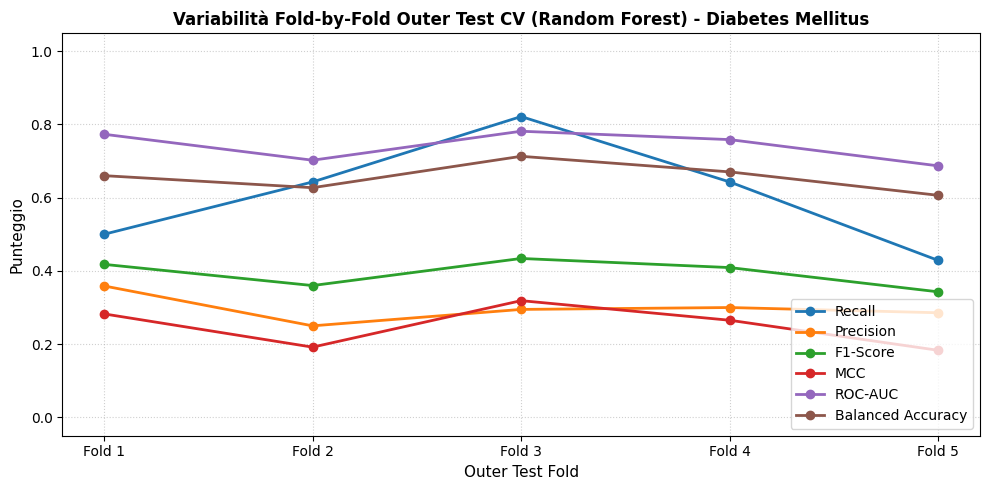

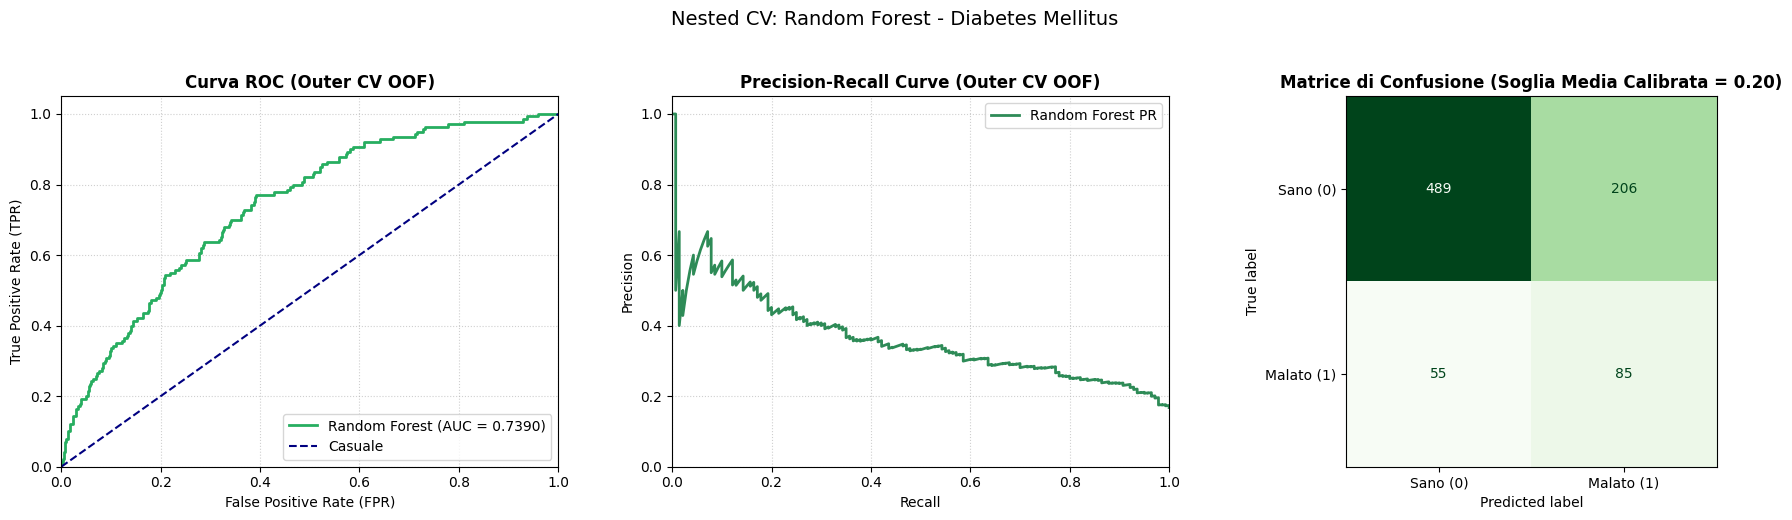


TOP 15 FEATURE PIÙ DETERMINANTI NESTED CV (RANDOM FOREST) - Diabetes Mellitus:
                                                                                                             Feature  Importanza Media  Std Importanza
                                                                                                           Hb (g/dl)            0.1568          0.0147
                                                                                                  Creatinina (mg/dl)            0.1331          0.0158
                                                                                                  Leucociti (10*9/L)            0.0904          0.0204
                                                                                             Circonferenza vita (cm)            0.0858          0.0100
                                                                                                         BMI (kg/m2)            0.0838          0.0038
              

In [30]:
# Random Forest

import numpy as np
import pandas as pd
from imblearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# Pipeline base per Random Forest
pipeline_rf = Pipeline([
    ('resampler', strategia),
    ('classifier', RandomForestClassifier(random_state=42, n_jobs=-1))
])

# Griglia degli iperparametri
param_grid_rf = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [5, 8, 12],
    'classifier__min_samples_leaf': [2, 5, 10],
    'classifier__min_samples_split': [2, 5],
    'classifier__max_features': ['sqrt']
}

# Valutazione
risultati_rf = valuta_nested_cv_completo(
    pipeline_base=pipeline_rf,
    param_grid=param_grid_rf,
    X=X_pulito,
    y=y_pulito,
    outer_cv=outer_cv,
    inner_cv=inner_cv,
    nome_modello='Random Forest',
    target_lavoro=target_lavoro,
    search_type='grid',
    scoring_inner='roc_auc',
    color_roc='#27ae60',
    color_pr='seagreen',
    cmap_cm='Greens'
)

risultati_dettagliati_modelli['Random Forest'] = risultati_rf['df_outer_folds']
df_benchmark_nested = pd.concat([df_benchmark_nested, risultati_rf['df_sommario_outer']], ignore_index=True)

# Calcolo della Feature Importance
nomi_features = X_pulito.columns if hasattr(X_pulito, 'columns') else [f'Feature_{i}' for i in range(X_pulito.shape[1])]
importanze_outer_folds = []

for fold_idx, (idx_tr, _) in enumerate(outer_cv.split(X_pulito, y_pulito)):
    X_tr_f = X_pulito.iloc[idx_tr]
    y_tr_f = np.array(y_pulito)[idx_tr]

    params_fold = risultati_rf['best_params'][fold_idx]
    pipe_fold = clone(pipeline_rf)
    pipe_fold.set_params(**params_fold)
    pipe_fold.fit(X_tr_f, y_tr_f)

    importanze_outer_folds.append(pipe_fold.named_steps['classifier'].feature_importances_)

importanze_matrix = np.array(importanze_outer_folds)
media_importanze = np.mean(importanze_matrix, axis=0)
std_importanze = np.std(importanze_matrix, axis=0)

df_importances_rf = pd.DataFrame({
    'Feature': nomi_features,
    'Importanza Media': media_importanze,
    'Std Importanza': std_importanze
}).sort_values(by='Importanza Media', ascending=False)

print("\n" + "=" * 80)
print(f"TOP 15 FEATURE PIÙ DETERMINANTI NESTED CV (RANDOM FOREST) - {target_lavoro}:")
print("=" * 80)
print(df_importances_rf.head(15).round(4).to_string(index=False))

print("\n" + "=" * 80)
print("BENCHMARK COMPARATIVO AGGIORNATO (MEDIA ± STD DEI TEST SET ESTERNI):")
print("=" * 80)
print(df_benchmark_nested.to_string(index=False))


============================== AVVIO NESTED CV: LightGBM (Arterial Hypertension) ==============================
Outer Fold 1 completato | Soglia cal.: 0.5183 | ROC-AUC: 0.7023 | F1: 0.0000 | MCC: -0.0200
Outer Fold 2 completato | Soglia cal.: 0.4161 | ROC-AUC: 0.7428 | F1: 0.0000 | MCC: -0.0163
Outer Fold 3 completato | Soglia cal.: 0.0067 | ROC-AUC: 0.8960 | F1: 0.2000 | MCC: 0.2591
Outer Fold 4 completato | Soglia cal.: 0.2219 | ROC-AUC: 0.5173 | F1: 0.0000 | MCC: -0.0285
Outer Fold 5 completato | Soglia cal.: 0.7316 | ROC-AUC: 0.5419 | F1: 0.0000 | MCC: 0.0000

--- VARIABILITÀ TEST NESTED CV PER FOLD (LightGBM) ---
            Accuracy  Balanced Accuracy  Recall  Precision  F1-Score     MCC  ROC-AUC  Soglia Calibrata
Outer Fold                                                                                             
Fold 1        0.9605             0.4913    0.00     0.0000       0.0 -0.0200   0.7023            0.5183
Fold 2        0.9661             0.4942    0.00     0.0000   

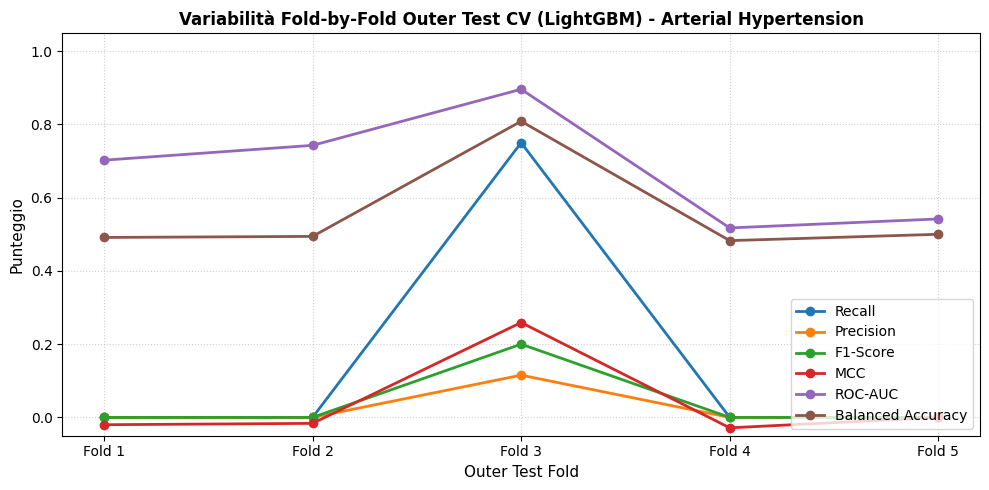

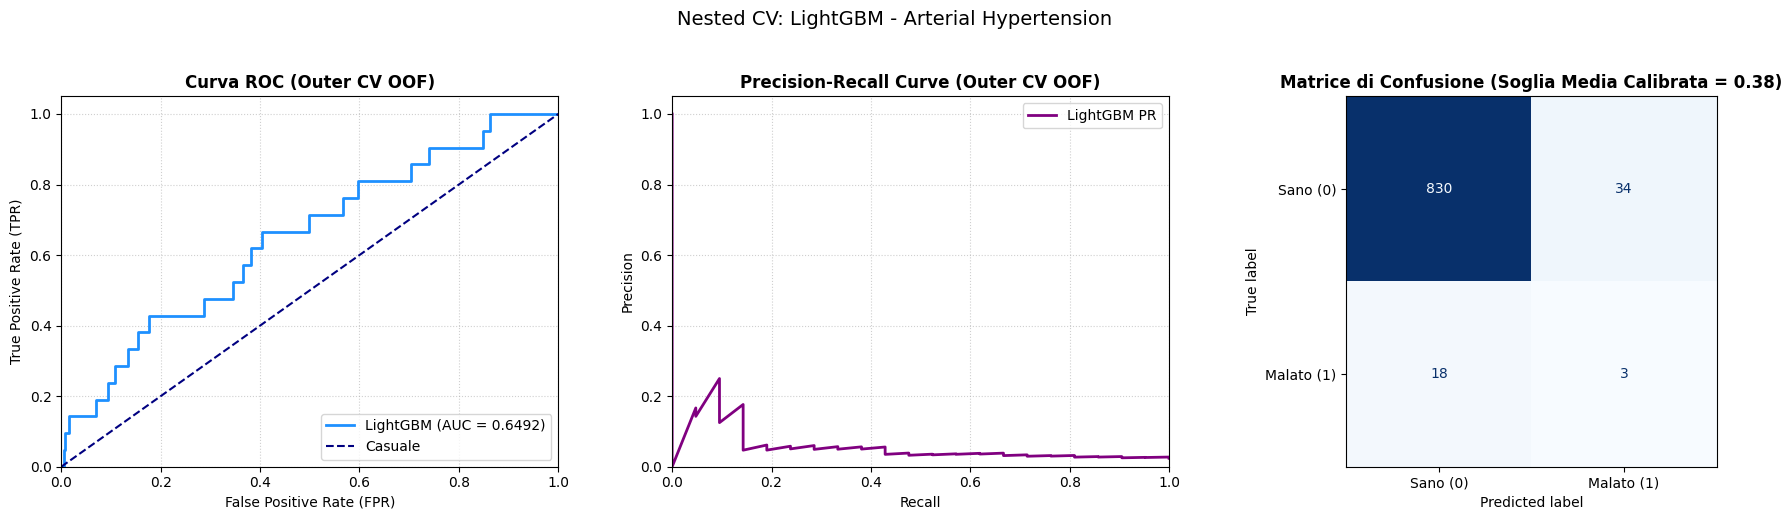


TOP 15 FEATURE PIÙ DETERMINANTI NESTED CV (LIGHTGBM) - Arterial Hypertension:
                                                                                                                                                                                                                                           Feature  Importanza Media  Std Importanza
                                                                                                                                                                                                                           Circonferenza_vita__cm_             294.8        136.7880
                                                                                              Considerando_che_i_legumi_si_possono_mangiare_o_con_la_pasta_riso_o_a_zuppa__quante_volte_a_settimana_li_mangi__piselli__ceci__fagioli__lenticchie_?             292.0         72.6774
                                                                                          

In [ ]:
# LightGBM

import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from imblearn.pipeline import Pipeline
from sklearn.base import clone

# Modifica caratteri per compatibilità con LightGBM
def clean_feature_names(df):
    cols = df.columns
    new_cols = []
    for col in cols:
        new_col = (
            str(col)
            .replace('[', '_')
            .replace(']', '_')
            .replace('<', '_')
            .replace('(', '_')
            .replace(')', '_')
            .replace(' ', '_')
            .replace('.', '_')
            .replace(',', '_')
            .replace(':', '_')
            .replace('/', '_')
        )
        new_cols.append(new_col)
    df_clean = df.copy()
    df_clean.columns = new_cols
    return df_clean

X_pulito_lgb = clean_feature_names(X_pulito)

# Definizione della Pipeline
pipeline_lgb = Pipeline([
    ('resampler', strategia),
    ('classifier', LGBMClassifier(random_state=42, verbosity=-1, n_jobs=-1))
    ])

# Iperparametri
param_grid_lgb = {
    'classifier__num_leaves': [15, 31],
    'classifier__max_depth': [3, 5],
    'classifier__learning_rate': [0.03, 0.1],
    'classifier__n_estimators': [100, 200],
    'classifier__subsample': [0.8, 1.0],
    'classifier__colsample_bytree': [0.8, 1.0]
}

# Valutazione
risultati_lgb = valuta_nested_cv_completo(
    pipeline_base=pipeline_lgb,
    param_grid=param_grid_lgb,
    X=X_pulito_lgb,
    y=y_pulito,
    outer_cv=outer_cv,
    inner_cv=inner_cv,
    nome_modello='LightGBM',
    target_lavoro=target_lavoro,
    search_type='grid',
    scoring_inner='roc_auc',
    color_roc='dodgerblue',
    color_pr='purple',
    cmap_cm='Blues'
)

risultati_dettagliati_modelli['LightGBM'] = risultati_lgb['df_outer_folds']
df_benchmark_nested = pd.concat([df_benchmark_nested, risultati_lgb['df_sommario_outer']], ignore_index=True)

# Calcolo della Feature Importance
nomi_features_lgb = X_pulito_lgb.columns
importanze_outer_lgb = []

for fold_idx, (idx_tr, _) in enumerate(outer_cv.split(X_pulito_lgb, y_pulito)):
    X_tr_f = X_pulito_lgb.iloc[idx_tr]
    y_tr_f = np.array(y_pulito)[idx_tr]

    params_fold = risultati_lgb['best_params'][fold_idx]
    pipe_fold = clone(pipeline_lgb)
    pipe_fold.set_params(**params_fold)
    pipe_fold.fit(X_tr_f, y_tr_f)

    importanze_outer_lgb.append(pipe_fold.named_steps['classifier'].feature_importances_)

importanze_matrix_lgb = np.array(importanze_outer_lgb)
media_importanze_lgb = np.mean(importanze_matrix_lgb, axis=0)
std_importanze_lgb = np.std(importanze_matrix_lgb, axis=0)

df_importances_lgb = pd.DataFrame({
    'Feature': nomi_features_lgb,
    'Importanza Media': media_importanze_lgb,
    'Std Importanza': std_importanze_lgb
}).sort_values(by='Importanza Media', ascending=False)

print("\n" + "=" * 80)
print(f"TOP 15 FEATURE PIÙ DETERMINANTI NESTED CV (LIGHTGBM) - {target_lavoro}:")
print("=" * 80)
print(df_importances_lgb.head(15).round(4).to_string(index=False))

print("\n" + "=" * 80)
print("BENCHMARK COMPARATIVO AGGIORNATO (MEDIA ± STD DEI TEST SET ESTERNI):")
print("=" * 80)
print(df_benchmark_nested.to_string(index=False))


============================== AVVIO NESTED CV: Logistic Regression (Arterial Hypertension) ==============================
Outer Fold 1 completato | Soglia cal.: 0.2153 | ROC-AUC: 0.7616 | F1: 0.1429 | MCC: 0.1274
Outer Fold 2 completato | Soglia cal.: 0.2093 | ROC-AUC: 0.8801 | F1: 0.2857 | MCC: 0.2745
Outer Fold 3 completato | Soglia cal.: 0.3573 | ROC-AUC: 0.7991 | F1: 0.3750 | MCC: 0.4126
Outer Fold 4 completato | Soglia cal.: 0.2168 | ROC-AUC: 0.7254 | F1: 0.0000 | MCC: -0.0259
Outer Fold 5 completato | Soglia cal.: 0.2823 | ROC-AUC: 0.5174 | F1: 0.1429 | MCC: 0.1158

--- VARIABILITÀ TEST NESTED CV PER FOLD (Logistic Regression) ---
            Accuracy  Balanced Accuracy  Recall  Precision  F1-Score     MCC  ROC-AUC  Soglia Calibrata
Outer Fold                                                                                             
Fold 1        0.9322             0.5990    0.25     0.1000    0.1429  0.1274   0.7616            0.2153
Fold 2        0.9718             0.6192  

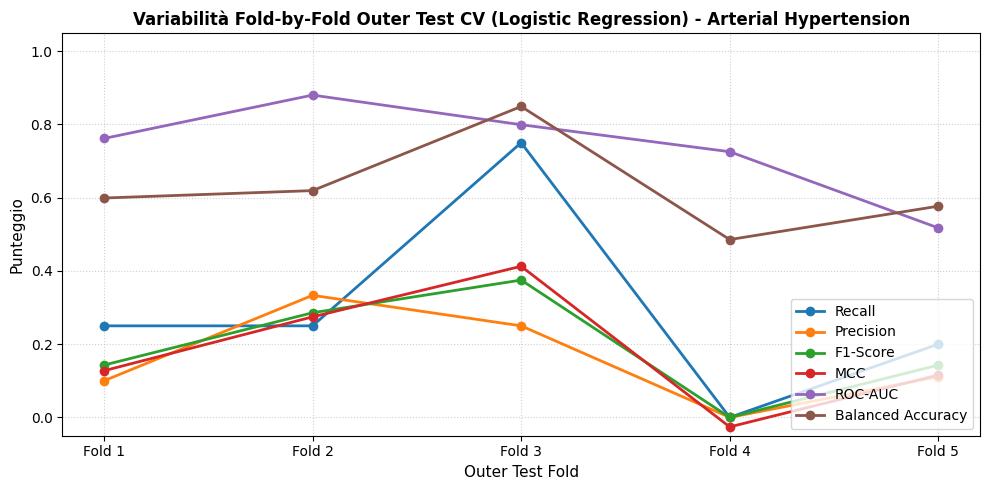

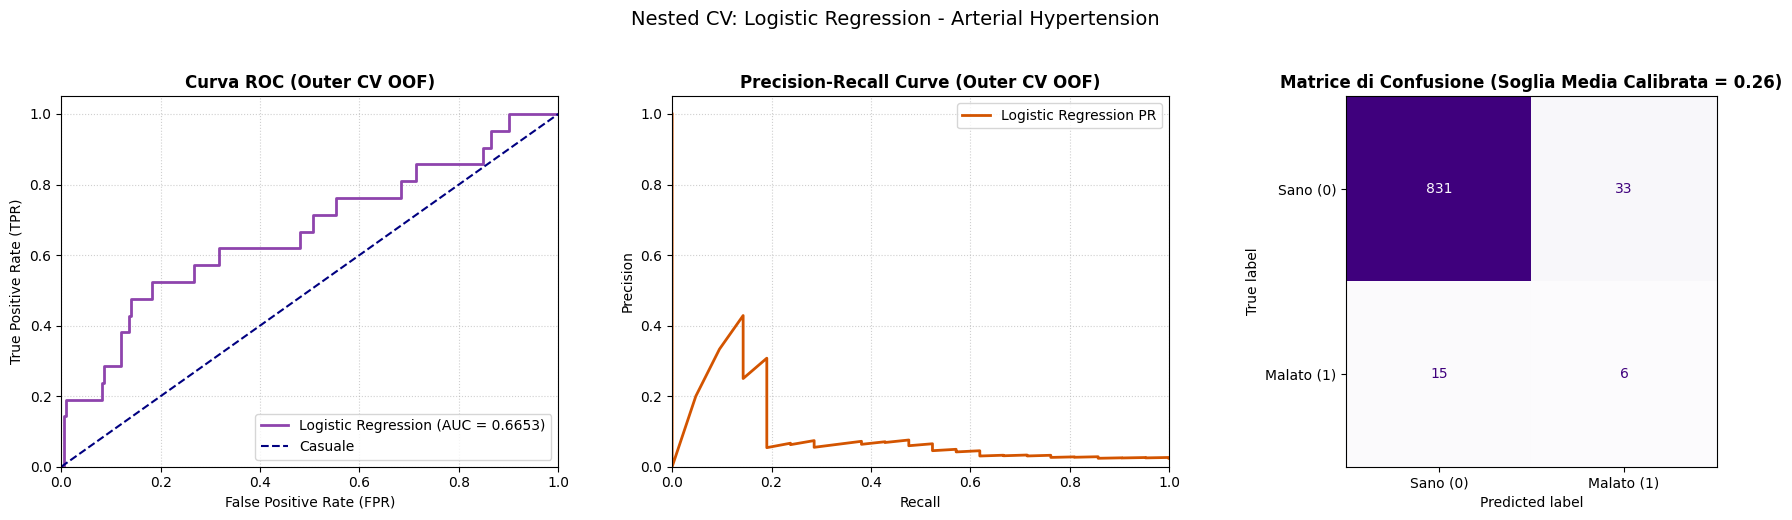


TABELLA ODDS RATIO NESTED CV (OR > 1: Rischio | OR < 1: Protettivo) - Arterial Hypertension:
                                                                                                                                             Feature  Beta Medio  Std Beta  OR Medio  Std OR
                                                                                                                  Pressione arteriosa sistolica mmHg      0.1938    0.1913    1.2380  0.2652
                                                                                                                             Circonferenza vita (cm)      0.0853    0.0447    1.0902  0.0501
                                                                                                                 Pressione arteriosa diastolica mmHg      0.0689    0.0655    1.0737  0.0729
Considerando che i legumi si possono mangiare o con la pasta/riso o a zuppa, quante volte a settimana li mangi (piselli, ceci, fagioli, lenticchie)?  

In [ ]:
# Regressione Logistica

from imblearn.pipeline import Pipeline
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

# Pipeline
pipeline_lr = Pipeline([
    ('resampler', strategia),
    (
        'classifier',
        LogisticRegression(max_iter=1000, random_state=42),
    ),
])

# Iperparametri
param_grid_lr = [
    {
        'classifier__penalty': ['l1'],
        'classifier__solver': ['liblinear', 'saga'],
        'classifier__C': np.logspace(-3, 2, 10),
    },
    {
        'classifier__penalty': ['l2'],
        'classifier__solver': ['lbfgs', 'newton-cg'],
        'classifier__C': np.logspace(-3, 2, 10),
    },
]

# Valutazione
risultati_lr = valuta_nested_cv_completo(
    pipeline_base=pipeline_lr,
    param_grid=param_grid_lr,
    X=X_pulito,
    y=y_pulito,
    outer_cv=outer_cv,
    inner_cv=inner_cv,
    nome_modello='Logistic Regression',
    target_lavoro=target_lavoro,
    search_type='grid',
    scoring_inner='roc_auc',
    color_roc='#8e44ad',
    color_pr='#d35400',
    cmap_cm='Purples',
)

risultati_dettagliati_modelli['Logistic Regression'] = risultati_lr[
    'df_outer_folds'
]
df_benchmark_nested = pd.concat(
    [df_benchmark_nested, risultati_lr['df_sommario_outer']], ignore_index=True
)

# Calcolo dei Coefficienti (Beta) e Odds Ratio (OR)
nomi_features_lr = (
    X_pulito.columns
    if hasattr(X_pulito, 'columns')
    else [f'Feature_{i}' for i in range(X_pulito.shape[1])]
)
coef_outer_folds = []

for fold_idx, (idx_tr, _) in enumerate(outer_cv.split(X_pulito, y_pulito)):
  X_tr_f = X_pulito.iloc[idx_tr]
  y_tr_f = np.array(y_pulito)[idx_tr]

  params_fold = risultati_lr['best_params'][fold_idx]
  pipe_fold = clone(pipeline_lr)
  pipe_fold.set_params(**params_fold)
  pipe_fold.fit(X_tr_f, y_tr_f)

  coef_outer_folds.append(pipe_fold.named_steps['classifier'].coef_[0])

coef_matrix = np.array(coef_outer_folds)
beta_mean = np.mean(coef_matrix, axis=0)
beta_std = np.std(coef_matrix, axis=0)
or_mean = np.mean(np.exp(coef_matrix), axis=0)
or_std = np.std(np.exp(coef_matrix), axis=0)

df_risultati_lr = pd.DataFrame({
    'Feature': nomi_features_lr,
    'Beta Medio': beta_mean,
    'Std Beta': beta_std,
    'OR Medio': or_mean,
    'Std OR': or_std,
}).sort_values(by='OR Medio', ascending=False)

print('\n' + '=' * 80)
print(
    'TABELLA ODDS RATIO NESTED CV (OR > 1: Rischio | OR < 1: Protettivo) -'
    f' {target_lavoro}:'
)
print('=' * 80)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
print(df_risultati_lr.head(15).round(4).to_string(index=False))

print('\n' + '=' * 80)
print('BENCHMARK COMPARATIVO AGGIORNATO (MEDIA ± STD DEI TEST SET ESTERNI):')
print('=' * 80)
print(df_benchmark_nested.to_string(index=False))


============================== AVVIO NESTED CV: SVM (Kernel RBF) (Arterial Hypertension) ==============================
Outer Fold 1 completato | Soglia cal.: 0.6300 | ROC-AUC: 0.8786 | F1: 0.1818 | MCC: 0.1642
Outer Fold 2 completato | Soglia cal.: 0.7725 | ROC-AUC: 0.8584 | F1: 0.2500 | MCC: 0.2327
Outer Fold 3 completato | Soglia cal.: 0.1312 | ROC-AUC: 0.8324 | F1: 0.1667 | MCC: 0.1859
Outer Fold 4 completato | Soglia cal.: 0.2859 | ROC-AUC: 0.4523 | F1: 0.0000 | MCC: -0.0331
Outer Fold 5 completato | Soglia cal.: 0.9327 | ROC-AUC: 0.6884 | F1: 0.0000 | MCC: -0.0129

--- VARIABILITÀ TEST NESTED CV PER FOLD (SVM (Kernel RBF)) ---
            Accuracy  Balanced Accuracy  Recall  Precision  F1-Score     MCC  ROC-AUC  Soglia Calibrata
Outer Fold                                                                                             
Fold 1        0.9492             0.6077    0.25     0.1429    0.1818  0.1642   0.8786            0.6300
Fold 2        0.9661             0.6163    0.2

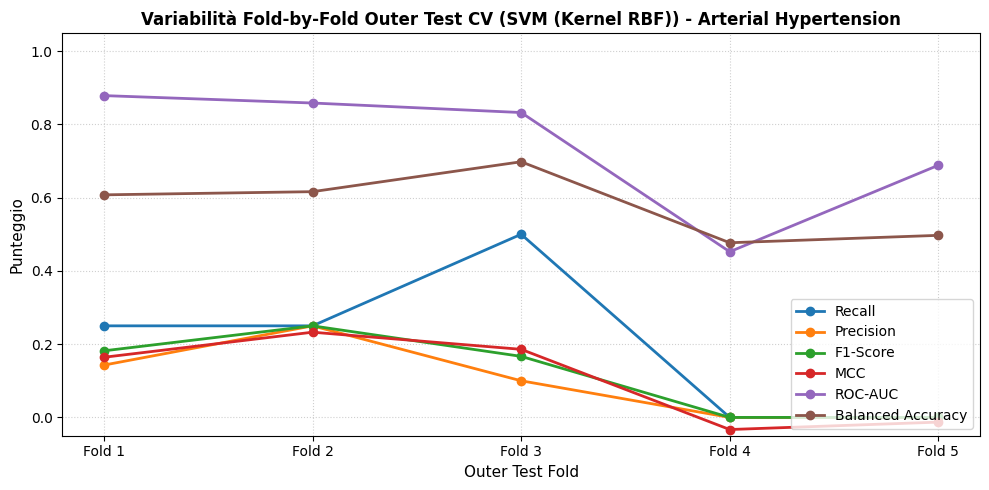

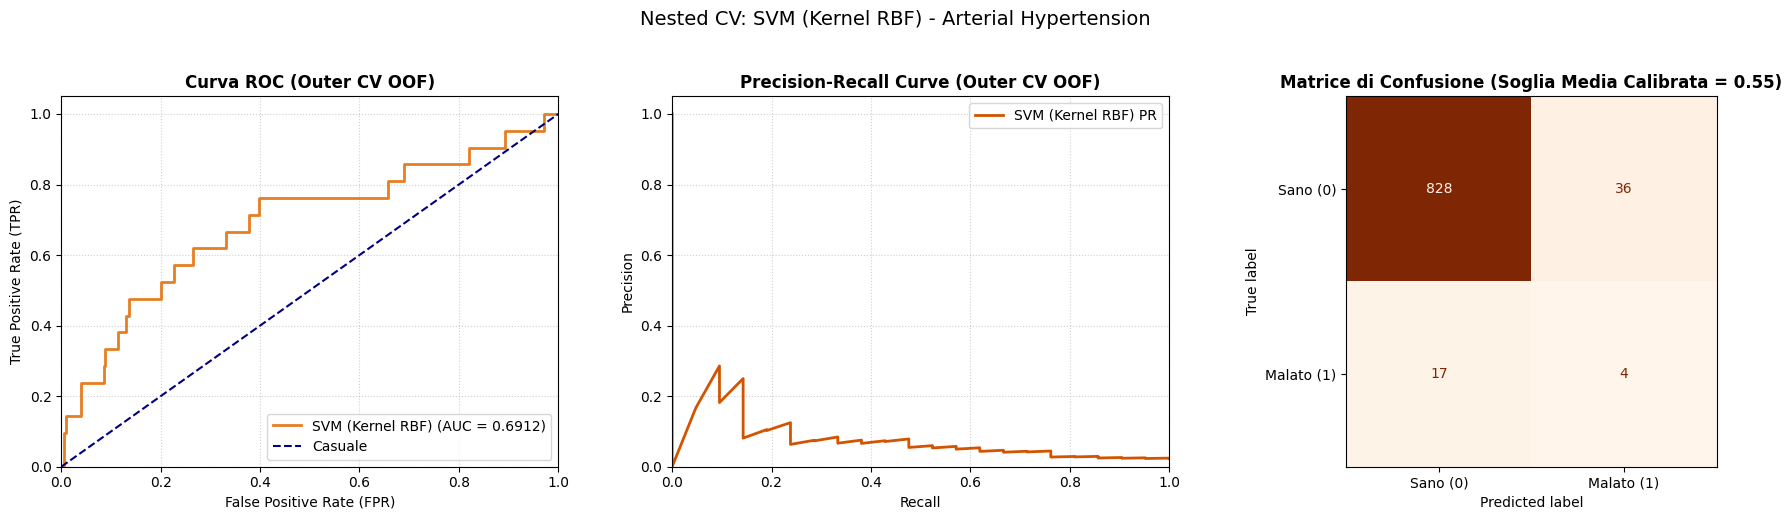


Calcolo Permutation Feature Importance sui test fold esterni in corso...

TOP 15 FEATURE PIÙ DETERMINANTI NESTED CV (PERMUTATION IMPORTANCE - SVM) - Arterial Hypertension:
                                                                                                                                                                                                                                           Feature  Importanza Media  Std Importanza
                                                                                                                                                                                                                Pressione_arteriosa_sistolica_mmHg            0.1370          0.1189
                                                                                                                                                                                                                           Circonferenza_vita__cm_            0.0556          0.0

In [ ]:
# SVC

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.svm import SVC
from imblearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Modifica caratteri per compatibilità
def clean_feature_names(df):
    cols = df.columns
    new_cols = []
    for col in cols:
        new_col = (
            str(col)
            .replace('[', '_')
            .replace(']', '_')
            .replace('<', '_')
            .replace('(', '_')
            .replace(')', '_')
            .replace(' ', '_')
            .replace('.', '_')
            .replace(',', '_')
            .replace(':', '_')
            .replace('/', '_')
        )
        new_cols.append(new_col)
    df_clean = df.copy()
    df_clean.columns = new_cols
    return df_clean

X_pulito_svm = clean_feature_names(X_pulito)
y_arr_svm = np.array(y_pulito)

# Pipeline
pipeline_svm = Pipeline([
    ('resampler', strategia),
    ('classifier', SVC(
        kernel='rbf',
        probability=True,
        random_state=42
    ))
])

# Iperparametri
param_grid_svm = {
    'classifier__C': [0.1, 1, 10, 50],
    'classifier__gamma': ['scale', 'auto', 0.01, 0.1]
}

# Valutazione
risultati_svm = valuta_nested_cv_completo(
    pipeline_base=pipeline_svm,
    param_grid=param_grid_svm,
    X=X_pulito_svm,
    y=y_arr_svm,
    outer_cv=outer_cv,
    inner_cv=inner_cv,
    nome_modello='SVM (Kernel RBF)',
    target_lavoro=target_lavoro,
    search_type='grid',
    scoring_inner='roc_auc',
    color_roc='#e67e22',
    color_pr='#d35400',
    cmap_cm='Oranges'
)

risultati_dettagliati_modelli['SVM (Kernel RBF)'] = risultati_svm['df_outer_folds']
df_benchmark_nested = pd.concat([df_benchmark_nested, risultati_svm['df_sommario_outer']], ignore_index=True)

# Permutation Feature Importance
nomi_features_svm = X_pulito_svm.columns
perm_means_outer = []

print("\nCalcolo Permutation Feature Importance sui test fold esterni in corso...")

for fold_idx, (idx_tr, idx_te) in enumerate(outer_cv.split(X_pulito_svm, y_arr_svm)):
    X_tr_f, X_te_f = X_pulito_svm.iloc[idx_tr], X_pulito_svm.iloc[idx_te]
    y_tr_f, y_te_f = y_arr_svm[idx_tr], y_arr_svm[idx_te]

    params_fold = risultati_svm['best_params'][fold_idx]
    pipe_fold = clone(pipeline_svm)
    pipe_fold.set_params(**params_fold)
    pipe_fold.fit(X_tr_f, y_tr_f)

    res_perm_fold = permutation_importance(
        pipe_fold,
        X_te_f,
        y_te_f,
        scoring='roc_auc',
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )
    perm_means_outer.append(res_perm_fold.importances_mean)

perm_matrix = np.array(perm_means_outer)
media_perm = np.mean(perm_matrix, axis=0)
std_perm = np.std(perm_matrix, axis=0)

df_importances_svm = pd.DataFrame({
    'Feature': nomi_features_svm,
    'Importanza Media': media_perm,
    'Std Importanza': std_perm
}).sort_values(by='Importanza Media', ascending=False)

print("\n" + "=" * 80)
print(f"TOP 15 FEATURE PIÙ DETERMINANTI NESTED CV (PERMUTATION IMPORTANCE - SVM) - {target_lavoro}:")
print("=" * 80)
print(df_importances_svm.head(15).round(4).to_string(index=False))

print("\n" + "=" * 80)
print("BENCHMARK COMPARATIVO AGGIORNATO (MEDIA ± STD DEI TEST SET ESTERNI):")
print("=" * 80)
print(df_benchmark_nested.to_string(index=False))


============================== AVVIO NESTED CV: Multi-Layer Perceptron (Arterial Hypertension) ==============================
Outer Fold 1 completato | Soglia cal.: 0.5076 | ROC-AUC: 0.6431 | F1: 0.0690 | MCC: 0.0475
Outer Fold 2 completato | Soglia cal.: 0.5389 | ROC-AUC: 0.8410 | F1: 0.0000 | MCC: 0.0000
Outer Fold 3 completato | Soglia cal.: 0.4003 | ROC-AUC: 0.8815 | F1: 0.2609 | MCC: 0.3157
Outer Fold 4 completato | Soglia cal.: 0.1970 | ROC-AUC: 0.4827 | F1: 0.1111 | MCC: 0.0963
Outer Fold 5 completato | Soglia cal.: 0.4938 | ROC-AUC: 0.5570 | F1: 0.1053 | MCC: 0.0764

--- VARIABILITÀ TEST NESTED CV PER FOLD (Multi-Layer Perceptron) ---
            Accuracy  Balanced Accuracy  Recall  Precision  F1-Score     MCC  ROC-AUC  Soglia Calibrata
Outer Fold                                                                                             
Fold 1        0.8475             0.5556    0.25     0.0400    0.0690  0.0475   0.6431            0.5076
Fold 2        0.9774             0.5

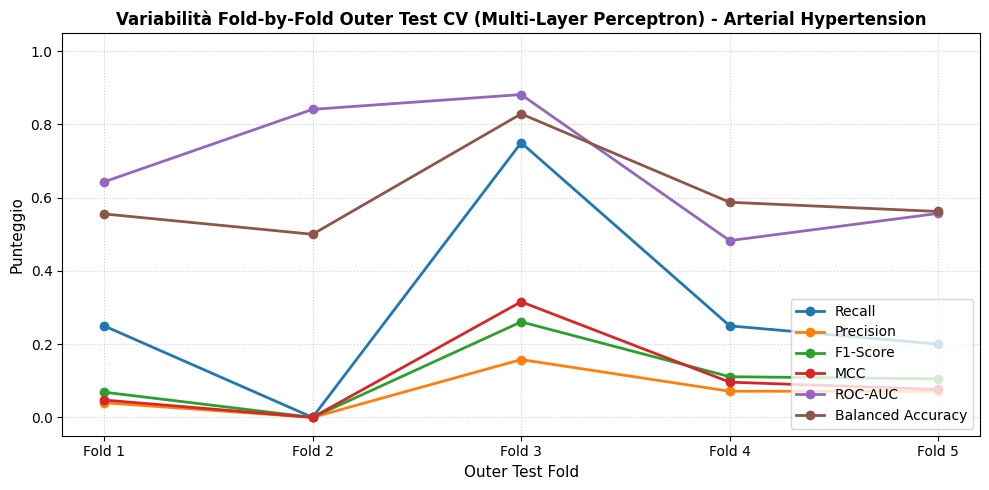

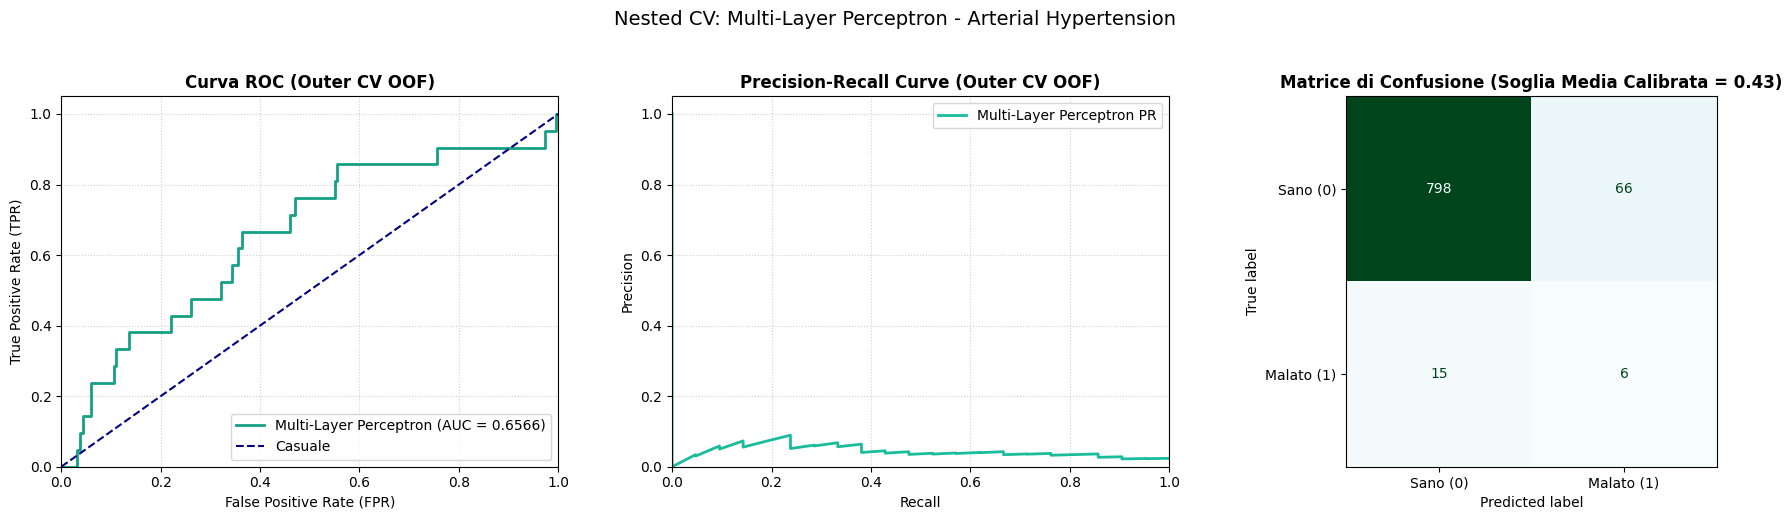


Calcolo Permutation Feature Importance (MLP) sui test fold esterni in corso...

TOP 15 FEATURE PIÙ DETERMINANTI NESTED CV (PERMUTATION IMPORTANCE - MLP) - Arterial Hypertension:
                                                                                                                                                                                                              Feature  Importanza Media  Std Importanza
                                                                                                                                                                                   Pressione arteriosa sistolica mmHg            0.0627          0.0228
Con le risorse finanziarie a tua disposizione (provenienti dal tuo reddito o da quello della tua famiglia), indichi con un voto da 1 a 5 quanto riesci a soddisfare le esigenze della tua attuale situazione di vita?            0.0438          0.0691
                                                                             

In [ ]:
#MLP

import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.neural_network import MLPClassifier
from imblearn.pipeline import Pipeline
from sklearn.inspection import permutation_importance

# Pipeline
pipeline_mlp = Pipeline([
    ('resampler', strategia),
    ('classifier', MLPClassifier(
        max_iter=1000,
        early_stopping=True,
        n_iter_no_change=15,
        random_state=42
    ))
])

# Iperparametri
param_grid_mlp = {
    'classifier__hidden_layer_sizes': [(32,), (64,), (32, 16), (64, 32)],
    'classifier__activation': ['relu', 'tanh'],
    'classifier__alpha': [0.0001, 0.01, 0.1, 1.0],
    'classifier__learning_rate_init': [0.001, 0.01],
}

# Valutazione
risultati_mlp = valuta_nested_cv_completo(
    pipeline_base=pipeline_mlp,
    param_grid=param_grid_mlp,
    X=X_pulito,
    y=y_pulito,
    outer_cv=outer_cv,
    inner_cv=inner_cv,
    nome_modello='Multi-Layer Perceptron',
    target_lavoro=target_lavoro,
    search_type='grid',
    scoring_inner='roc_auc',
    color_roc='#16a085',
    color_pr='#1abc9c',
    cmap_cm='BuGn'
)

risultati_dettagliati_modelli['Multi-Layer Perceptron'] = risultati_mlp['df_outer_folds']
df_benchmark_nested = pd.concat([df_benchmark_nested, risultati_mlp['df_sommario_outer']], ignore_index=True)

# Permutation Feature Importance
nomi_features_mlp = X_pulito.columns if hasattr(X_pulito, 'columns') else [f'Feature_{i}' for i in range(X_pulito.shape[1])]
y_arr_mlp = np.array(y_pulito)
perm_means_outer_mlp = []

print("\nCalcolo Permutation Feature Importance (MLP) sui test fold esterni in corso...")

for fold_idx, (idx_tr, idx_te) in enumerate(outer_cv.split(X_pulito, y_arr_mlp)):
    X_tr_f, X_te_f = X_pulito.iloc[idx_tr], X_pulito.iloc[idx_te]
    y_tr_f, y_te_f = y_arr_mlp[idx_tr], y_arr_mlp[idx_te]

    params_fold = risultati_mlp['best_params'][fold_idx]
    pipe_fold = clone(pipeline_mlp)
    pipe_fold.set_params(**params_fold)
    pipe_fold.fit(X_tr_f, y_tr_f)

    res_perm_fold = permutation_importance(
        pipe_fold,
        X_te_f,
        y_te_f,
        scoring='roc_auc',
        n_repeats=5,
        random_state=42,
        n_jobs=-1
    )
    perm_means_outer_mlp.append(res_perm_fold.importances_mean)

perm_matrix_mlp = np.array(perm_means_outer_mlp)
media_perm_mlp = np.mean(perm_matrix_mlp, axis=0)
std_perm_mlp = np.std(perm_matrix_mlp, axis=0)

df_importances_mlp = pd.DataFrame({
    'Feature': nomi_features_mlp,
    'Importanza Media': media_perm_mlp,
    'Std Importanza': std_perm_mlp
}).sort_values(by='Importanza Media', ascending=False)

print("\n" + "=" * 80)
print(f"TOP 15 FEATURE PIÙ DETERMINANTI NESTED CV (PERMUTATION IMPORTANCE - MLP) - {target_lavoro}:")
print("=" * 80)
print(df_importances_mlp.head(15).round(4).to_string(index=False))

print("\n" + "=" * 80)
print("BENCHMARK COMPARATIVO COMPLETO AGGIORNATO (MEDIA ± STD DEI TEST SET ESTERNI):")
print("=" * 80)
print(df_benchmark_nested.to_string(index=False))

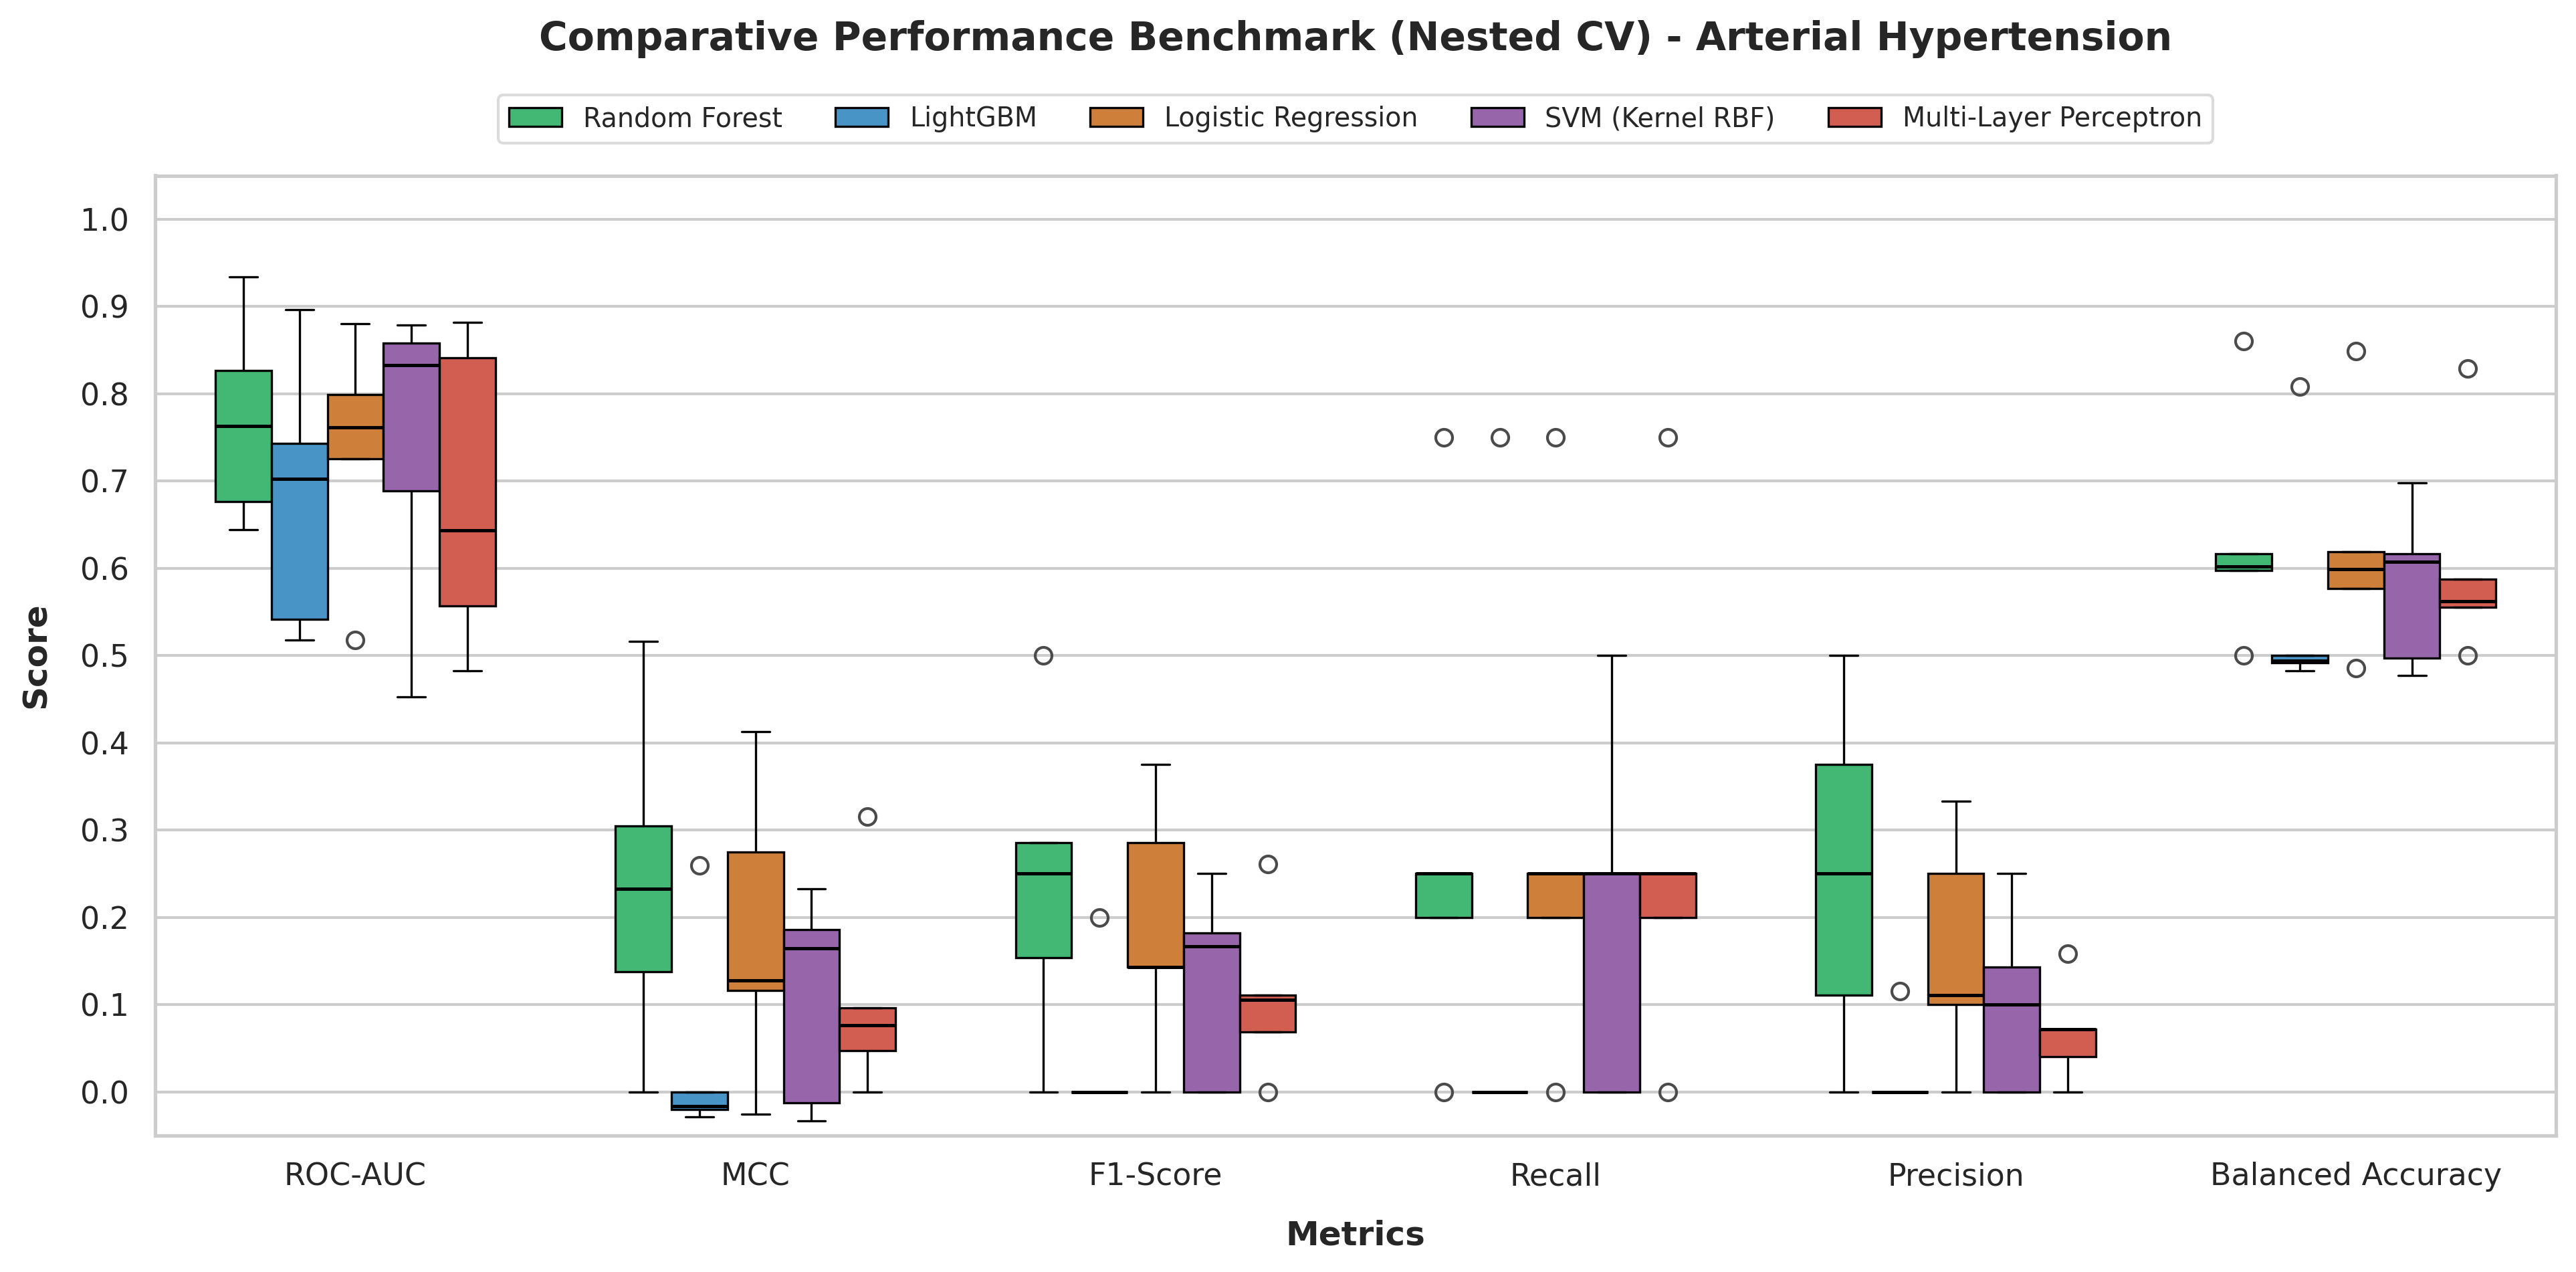

In [ ]:
# Comparazione metriche

import seaborn as sns

# Unione delle metriche di tutti i modelli
df_list = []
for nome_modello, df_fold in risultati_dettagliati_modelli.items():
  temp_df = df_fold.copy()
  temp_df['Modello'] = nome_modello
  df_list.append(temp_df)

df_all_folds = pd.concat(df_list, axis=0)

metriche = [
    'ROC-AUC',
    'MCC',
    'F1-Score',
    'Recall',
    'Precision',
    'Balanced Accuracy',
]

df_plot = pd.melt(
    df_all_folds,
    id_vars=['Modello'],
    value_vars=metriche,
    var_name='Metrica',
    value_name='Valore',
)

plt.figure(figsize=(13, 6.5), dpi=300)
sns.set_theme(style='whitegrid')

palette_modelli = {
    'Random Forest': '#2ecc71',
    'LightGBM': '#3498db',
    'Logistic Regression': '#e67e22',
    'SVM (Kernel RBF)': '#9b59b6',
    'Multi-Layer Perceptron': '#e74c3c',
}

# Boxplot di Seaborn
ax = sns.boxplot(
    data=df_plot,
    x='Metrica',
    y='Valore',
    hue='Modello',
    palette=palette_modelli,
    boxprops={'edgecolor': 'black', 'linewidth': 0.8},
    whiskerprops={'color': 'black', 'linewidth': 0.8},
    capprops={'color': 'black', 'linewidth': 0.8},
    medianprops={'color': 'black', 'linewidth': 1.2},
    width=0.7,
)

plt.title(
    f'Comparative Performance Benchmark (Nested CV) - {target_lavoro}',
    fontsize=14,
    pad=45,
    fontweight='bold',
)

plt.legend(
    title=None,
    loc='lower center',
    bbox_to_anchor=(0.5, 1.02),
    ncol=5,
    frameon=True,
    facecolor='white',
    edgecolor='lightgray',
    fontsize=9.5,
)

plt.xlabel('Metrics', fontsize=12, labelpad=10, fontweight='semibold')
plt.ylabel('Score', fontsize=12, labelpad=10, fontweight='semibold')
plt.ylim(-0.05, 1.05)
plt.yticks([i / 10 for i in range(11)])

plt.tight_layout()
plt.show()

In [ ]:
df_all_folds.groupby('Modello').mean().round(3)

,Accuracy,Balanced Accuracy,Recall,Precision,F1-Score,MCC,ROC-AUC,Soglia Calibrata
Modello,,,,,,,,
LightGBM,0.941,0.555,0.15,0.023,0.040,0.039,0.680,0.379
Logistic Regression,0.946,0.626,0.29,0.159,0.189,0.181,0.737,0.256
Multi-Layer Perceptron,0.908,0.607,0.29,0.068,0.109,0.107,0.681,0.428
Random Forest,0.964,0.635,0.29,0.247,0.238,0.238,0.769,0.395
SVM (Kernel RBF),0.940,0.579,0.20,0.099,0.120,0.107,0.742,0.550


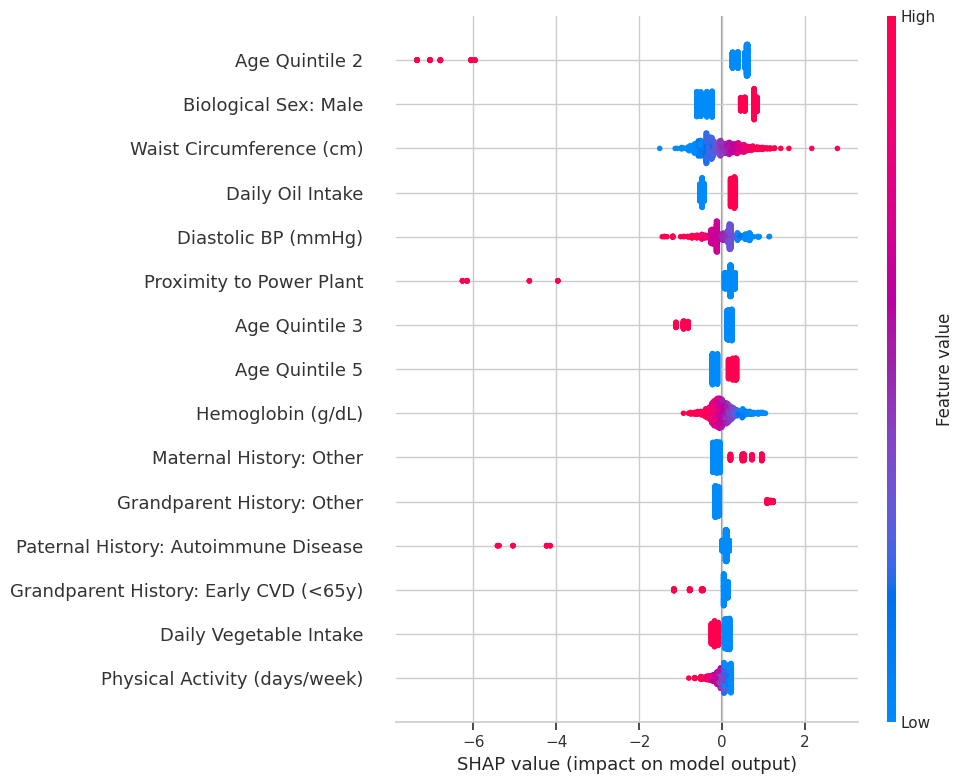

In [ ]:
# Calcolo valori shap per Regressione Logistica

import shap
import numpy as np
import pandas as pd
from sklearn.base import clone

shap_values_lr_list = []
test_indices_lr_list = []

for fold_idx, (idx_tr, idx_te) in enumerate(outer_cv.split(X_pulito, y_pulito)):
    X_tr_f = X_pulito.iloc[idx_tr]
    y_tr_f = np.array(y_pulito)[idx_tr]
    X_te_f = X_pulito.iloc[idx_te]

    # Fit del modello ottimizzato sul fold
    params_fold = risultati_lr['best_params'][fold_idx]
    pipe_fold = clone(pipeline_lr)
    pipe_fold.set_params(**params_fold)
    pipe_fold.fit(X_tr_f, y_tr_f)

    lr_model = pipe_fold.named_steps['classifier']

    # Masker sui dati di training non sintetici per evitare distorsioni di densità
    masker = shap.maskers.Independent(data=X_tr_f)
    explainer = shap.LinearExplainer(lr_model, masker=masker)
    sv_fold = explainer(X_te_f)

    val = sv_fold.values
    if hasattr(val, 'ndim') and val.ndim == 3:
        sv_fold_vals = val[:, :, 1]
    else:
        sv_fold_vals = val

    shap_values_lr_list.append(sv_fold_vals)
    test_indices_lr_list.append(idx_te)

all_test_idx_lr = np.concatenate(test_indices_lr_list)
all_shap_lr = np.vstack(shap_values_lr_list)
X_test_all_lr = X_pulito.iloc[all_test_idx_lr].copy()

shap.summary_plot(
    all_shap_lr,
    X_test_all_lr,
    max_display=15,
    plot_size=(10, 8),
    show=True
)


Calcolo SHAP values Out-of-Fold (KernelExplainer) in corso...


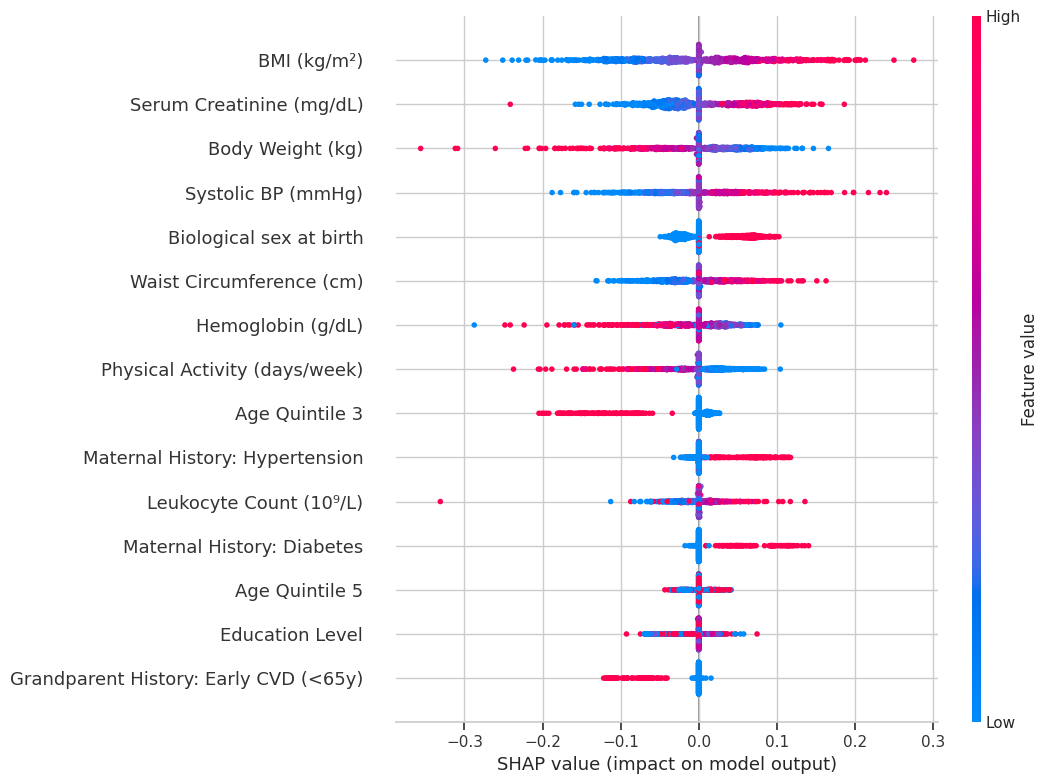

In [ ]:
# Calcolo valori shap per svc

import shap

shap_values_svc_list = []
test_indices_svc_list = []

for fold_idx, (idx_tr, idx_te) in enumerate(outer_cv.split(X_pulito_svm, y_arr_svm)):
    X_tr_f, X_te_f = X_pulito_svm.iloc[idx_tr], X_pulito_svm.iloc[idx_te]
    y_tr_f = y_arr_svm[idx_tr]

    # Ricostruzione e training della pipeline ottimizzata per il fold
    params_fold = risultati_svm['best_params'][fold_idx]
    pipe_fold = clone(pipeline_svm)
    pipe_fold.set_params(**params_fold)
    pipe_fold.fit(X_tr_f, y_tr_f)

    def model_predict_proba(data):
        df_input = pd.DataFrame(data, columns=X_pulito_svm.columns)
        return pipe_fold.predict_proba(df_input)[:, 1]

    background_summary = shap.kmeans(X_tr_f, 25)

    explainer = shap.KernelExplainer(model_predict_proba, background_summary)

    sv_fold = explainer.shap_values(X_te_f, nsamples=100, silent=True)

    shap_values_svc_list.append(sv_fold)
    test_indices_svc_list.append(idx_te)

all_test_idx_svc = np.concatenate(test_indices_svc_list)
all_shap_svc = np.vstack(shap_values_svc_list)
X_test_all_svc = X_pulito_svm.iloc[all_test_idx_svc].copy()

plt.figure(figsize=(11, 8))
shap.summary_plot(
    all_shap_svc,
    X_test_all_svc,
    max_display=15,
    plot_size=(11, 8),
    show=True
)

/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:1150: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


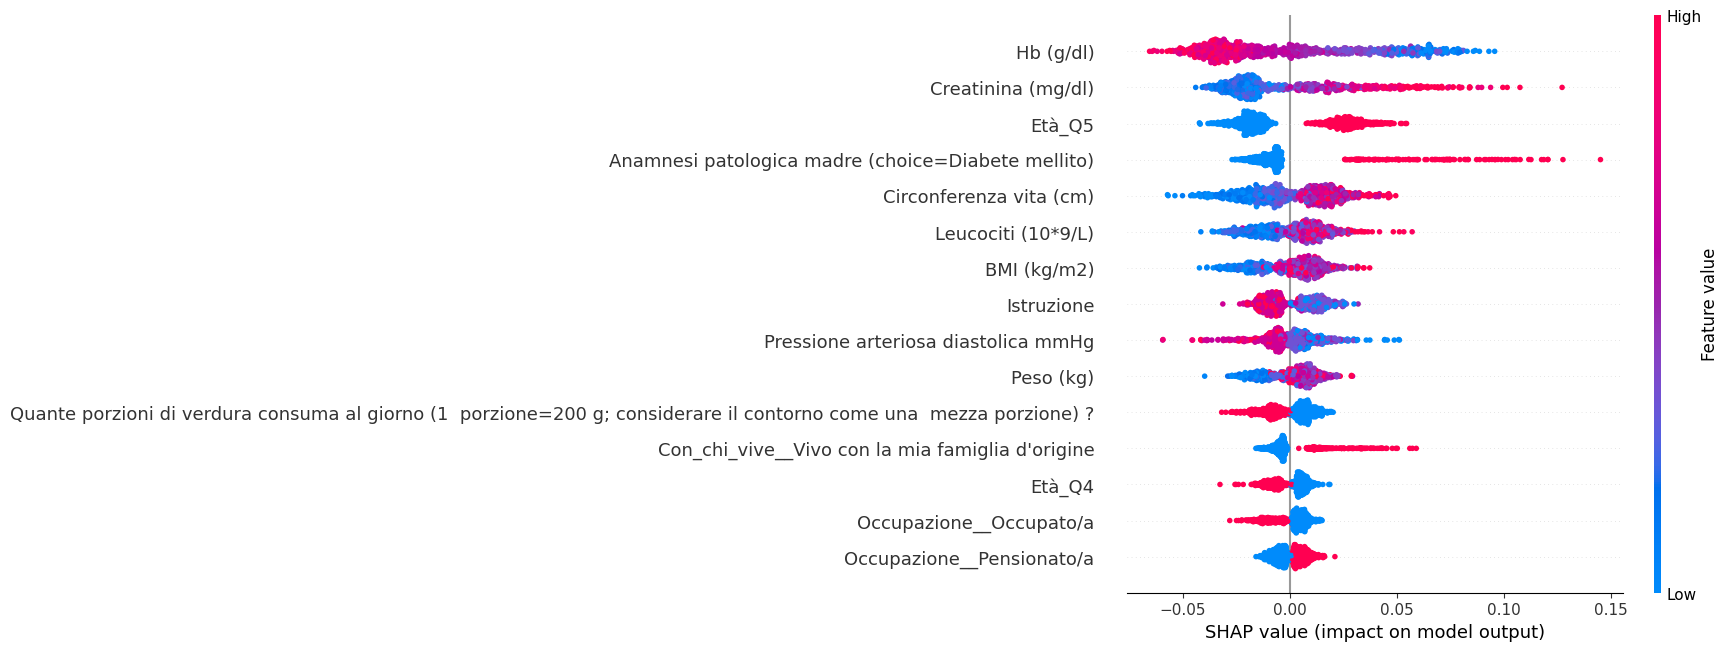

In [31]:
# Calcolo valori SHAP per Random Forest

import shap

shap_values_list = []
test_indices_list = []

for fold_idx, (idx_tr, idx_te) in enumerate(outer_cv.split(X_pulito, y_pulito)):
    X_tr_f = X_pulito.iloc[idx_tr]
    y_tr_f = np.array(y_pulito)[idx_tr]
    X_te_f = X_pulito.iloc[idx_te]

    # Ricostruzione e training della pipeline ottimizzata per il fold
    params_fold = risultati_rf['best_params'][fold_idx]
    pipe_fold = clone(pipeline_rf)
    pipe_fold.set_params(**params_fold)
    pipe_fold.fit(X_tr_f, y_tr_f)

    # Estrazione del classificatore Random Forest addestrato
    rf_model = pipe_fold.named_steps['classifier']

    # Calcolo dei valori SHAP sui dati di test non visti del fold
    explainer = shap.TreeExplainer(rf_model)
    sv_fold = explainer.shap_values(X_te_f)

    # Gestione del formato di output per la classe positiva (Dislipidemia = 1)
    if isinstance(sv_fold, list):
        sv_fold = sv_fold[1]
    elif hasattr(sv_fold, 'ndim') and sv_fold.ndim == 3:
        sv_fold = sv_fold[:, :, 1]
    elif hasattr(sv_fold, 'values'):
        val = sv_fold.values
        sv_fold = val[:, :, 1] if (hasattr(val, 'ndim') and val.ndim == 3) else val

    shap_values_list.append(sv_fold)
    test_indices_list.append(idx_te)

# Concatenazione Out-of-Fold nell'ordine dei dati
all_test_indices = np.concatenate(test_indices_list)
all_shap_values = np.vstack(shap_values_list)
X_test_all = X_pulito.iloc[all_test_indices].copy()

shap.summary_plot(
    all_shap_values,
    X_test_all,
    max_display=15,
    show=True
)